In [588]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import config_BREAQ
import matplotlib.ticker as ScalarFormatter
import math
import scipy.stats as stats

In [589]:
font={'family':'serif','weight':'bold','size':12}
mpl.rc('font',**font)
mpl.rcParams['mathtext.default']='regular'

In [590]:
## CLT01
fig_title = '1-Flertex-GO-DF-RIB-PS'
fig_title_2 = '1-Flertex-GO-DF-RIB-PS (Dp≥ 100 nm)'

## CLTold
# fig_title = '11-Flertex-GOold-DF-RIB-PS'
# fig_title_2 = '11-Flertex-GOold-DF-RIB-PS (Dp≥ 100 nm)'

#RIB_PS
energy_total_per_braking = 1.48 #MJ
distance_total_per_braking = 2.12 #km

fact_scale = 1.72e6 
Iron_oxide_density = 5.24 #g/cm3

### Reading Inlet files

In [591]:
EP_OPS_in = pd.read_csv(config_BREAQ.filepath_OPS_in+r'\OPS_Normalized_IN.csv', sep=';', index_col=0, dtype=float)
EP_EEPS_in = pd.read_csv(config_BREAQ.filepath_EEPS+r'\EEPS_Normalized_Merged.csv', sep=';', index_col=0, dtype=float)
VF_EEPS_in = pd.read_csv(config_BREAQ.filepath_EEPS+r'\EEPS_Speed_Force_Merged.csv', sep=';', index_col=0, dtype=float)

### Reading Outlet files

In [592]:
EP_OPS_out = pd.read_csv(config_BREAQ.filepath_OPS_out+r'\OPS_Normalized_OUT.csv', sep=';', index_col=0, dtype=float)
EP_FMPS_out = pd.read_csv(config_BREAQ.filepath_FMPS+r'\FMPS_Normalized_Merged.csv', sep=';', index_col=0, dtype=float)
VF_FMPS_out = pd.read_csv(config_BREAQ.filepath_FMPS+r'\FMPS_Speed_Force_Merged.csv', sep=';', index_col=0, dtype=float)
EP_FMPS_out_corr = pd.read_csv(config_BREAQ.filepath_FMPS+r'\FMPS_Normalized_Corrected.csv', sep=';', index_col=0, dtype=float)

### Synchronization = start all at the 1st braking

In [593]:
synchro = 0
t_e = 0
for i in range(1,len(VF_EEPS_in)):
    if VF_EEPS_in['Force N [N]'].iloc[i] - VF_EEPS_in['Force N [N]'].iloc[i-1] > 1000:
        t_e = i-5
        break

t_s = 0
for i in range(1,len(VF_FMPS_out)):
    if VF_FMPS_out['Force N [N]'].iloc[i] - VF_FMPS_out['Force N [N]'].iloc[i-1] > 1000:
        t_s =i-5
        break

synchro = t_s-t_e

In [594]:
VF_EEPS_in = VF_EEPS_in.iloc[int(t_e):]
VF_EEPS_in.reset_index(inplace=True, drop=True)

EP_EEPS_in = EP_EEPS_in.iloc[int(t_e):]
EP_EEPS_in.reset_index(inplace=True, drop=True)

EP_OPS_in = EP_OPS_in.iloc[int(t_e):]
EP_OPS_in.reset_index(inplace=True, drop=True)

VF_FMPS_out = VF_FMPS_out.iloc[int(t_s):]
VF_FMPS_out.reset_index(inplace=True, drop=True)

EP_FMPS_out = EP_FMPS_out.iloc[int(t_s+5):]
EP_FMPS_out.reset_index(inplace=True, drop=True)

EP_FMPS_out_corr = EP_FMPS_out_corr.iloc[int(t_s+5):]
EP_FMPS_out_corr.reset_index(inplace=True, drop=True)

EP_OPS_out = EP_OPS_out.iloc[int(t_s-2):]
EP_OPS_out.reset_index(inplace=True, drop=True)

### Cutting the end

Inlet

In [595]:
# detecting last braking on EEPS
t_end = 0
for i in range(1,len(VF_EEPS_in)):
    if VF_EEPS_in['Force N [N]'].iloc[i] - VF_EEPS_in['Force N [N]'].iloc[i-1]< -1000:
        t_end = i+5

In [596]:
EP_EEPS_in = EP_EEPS_in.iloc[:t_end]
#EP_OPS_in = EP_OPS_in.iloc[:t_end]
EP_OPS_in = EP_OPS_in.iloc[:len(EP_FMPS_out_corr)]
VF_EEPS_in = VF_EEPS_in.iloc[:t_end]

Outlet

In [597]:
EP_FMPS_out = EP_FMPS_out[:len(EP_FMPS_out_corr)]
EP_OPS_out = EP_OPS_out[:len(EP_FMPS_out_corr)]
VF_FMPS_out = VF_FMPS_out[:len(EP_FMPS_out_corr)]

# Detection of brakings

##### Nb of braking for all test

In [598]:
# df_brakings = pd.DataFrame(columns=['Start','End'])
# d = {'Start':0,'End':0}
# for i in range(1,len(VF_FMPS_out)):
#     if (VF_FMPS_out['Force N [N]'].iloc[i-1]<2500) & (VF_FMPS_out['Force N [N]'].iloc[i]>2500) & (d['End']==0):
#         d['Start'] = i
#     if (VF_FMPS_out['Force N [N]'].iloc[i-1]>2500) & (VF_FMPS_out['Force N [N]'].iloc[i]<2500) & (d['Start']!=0):
#         d['End'] = i
#         df_brakings.loc[len(df_brakings)] = d
#         d = {'Start':0,'End':0}

In [599]:
df_brakings = pd.DataFrame(columns=['Start','End'])
d = {'Start':0,'End':0}
for i in range(1,len(VF_FMPS_out)):
    if (VF_FMPS_out['Force N [N]'].iloc[i-1]<2500) & (VF_FMPS_out['Force N [N]'].iloc[i]>2500) & (d['End']==0) & (d['Start']==0):
        d['Start'] = i-3
    if (VF_FMPS_out['Force N [N]'].iloc[i-1]>2500) & (VF_FMPS_out['Force N [N]'].iloc[i]<2500) & (d['Start']!=0):
        d['End'] = i+3
        df_brakings.loc[len(df_brakings)] = d
        d = {'Start':0,'End':0}

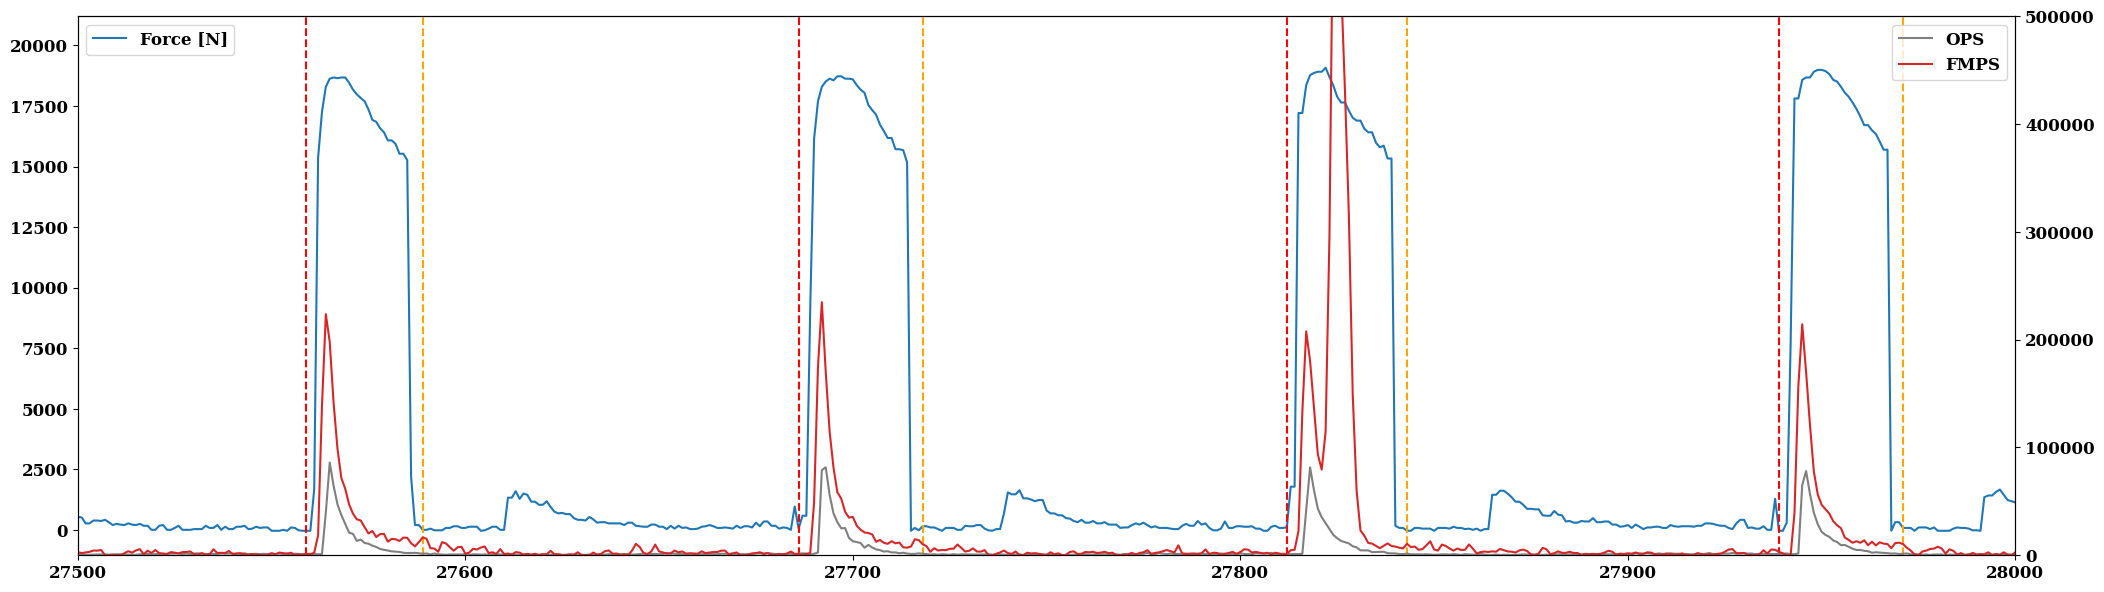

In [600]:
fig,ax = plt.subplots()
fig.set_size_inches(w=25,h=7)
ax1 = ax.twinx()

ax.plot(VF_FMPS_out.index,VF_FMPS_out['Force N [N]'], label='Force [N]')
ax1.plot(EP_OPS_out.index, EP_OPS_out.sum(axis=1),color='tab:grey', label='OPS')
ax1.plot(EP_FMPS_out_corr.index, EP_FMPS_out_corr.sum(axis=1),color='tab:red', label='FMPS')

for i in range(len(df_brakings)):
    ax.axvline(x=df_brakings['Start'].iloc[i], color='red', ls='--')
    ax.axvline(x=df_brakings['End'].iloc[i], color='orange', ls='--')
ax1.set_ylim(0,5E5)
ax.set_xlim(27500,28000)
ax.legend(loc='upper left')
ax1.legend(loc='upper right')

#### Calcul volume for FMPS and OPS in nm3/cm3

In [601]:
EP_FMPS_out_volume = EP_FMPS_out_corr.copy()
for col in EP_FMPS_out_volume.columns:
    v =(4/3) * np.pi * np.power(float(col)/2,3)
    EP_FMPS_out_volume[col]=EP_FMPS_out_volume[col]*v

EP_OPS_out_volume = EP_OPS_out.copy()
for col in EP_OPS_out_volume.columns:
    v =(4/3) * np.pi * np.power(float(col)*1000/2,3)
    EP_OPS_out_volume[col]=EP_OPS_out_volume[col]*v

#### Calcul mass for FMPS and OPS in µg/cm3 

In [602]:
EP_FMPS_out_mass = EP_FMPS_out_volume.copy()
for col in EP_FMPS_out_mass.columns:
    EP_FMPS_out_mass[col]=EP_FMPS_out_mass[col] * 1E-21 * Iron_oxide_density *1e6 # en µg/cm3


EP_OPS_out_mass = EP_OPS_out_volume.copy()
for col in EP_OPS_out_mass.columns:
    EP_OPS_out_mass[col]=EP_OPS_out_mass[col] * 1E-21 * Iron_oxide_density *1e6 # en µg/cm3

### Removing braking under threshold

In [603]:
# threshold = 14400  #CkLTold_RIB-PS_18-09-2024
threshold = 7200 # CLT01_RIB-PS_24-09-2024

 
df_brakings_limit = df_brakings[df_brakings['Start']>threshold]

In [604]:
EP_FMPS_out_limit = EP_FMPS_out_corr.iloc[int(df_brakings_limit['Start'].iloc[0]):]
EP_OPS_out_limit = EP_OPS_out.iloc[int(df_brakings_limit['Start'].iloc[0]):]

EP_FMPS_out_volume_limit = EP_FMPS_out_volume.iloc[int(df_brakings_limit['Start'].iloc[0]):]
EP_OPS_out_volume_limit = EP_OPS_out_volume.iloc[int(df_brakings_limit['Start'].iloc[0]):]

EP_FMPS_out_mass_limit = EP_FMPS_out_mass.iloc[int(df_brakings_limit['Start'].iloc[0]):]
EP_OPS_out_mass_limit = EP_OPS_out_mass.iloc[int(df_brakings_limit['Start'].iloc[0]):]

#### Calcul total energy et distance for RIB-PS

In [605]:
total_energy = energy_total_per_braking * len(df_brakings)
total_distance = distance_total_per_braking * len(df_brakings)

total_energy_limit = energy_total_per_braking * len(df_brakings_limit)
total_distance_limit = distance_total_per_braking * len(df_brakings_limit)

# Outlet

In [606]:
# fig = plt.figure(figsize=(50,40))
# gs = gridspec.GridSpec(ncols=1, nrows=4, figure=fig)

# ax0 = fig.add_subplot(gs[0,0])
# ax1 = fig.add_subplot(gs[1,0])
# ax2 = fig.add_subplot(gs[2,0])
# ax3 = fig.add_subplot(gs[3,0])

# ax0.plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1), color='darkblue')
# ax1.plot(EP_FMPS_out.index/3600,EP_FMPS_out.sum(axis=1))
# ax2.plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr.sum(axis=1))
# ax3.plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr.sum(axis=1))

# ax0.margins(x=0, y=0)
# ax1.margins(x=0)
# ax2.margins(x=0)
# ax3.margins(x=0, y=0)

# ax0.sharex(ax1)
# ax2.sharex(ax1)
# ax3.sharex(ax1)

# ax0.set_xlim(0,4.4)

# ax0.set_ylim(0,4E4)
# ax1.set_yscale('log')
# ax1.set_ylim(1E3,1E6)
# ax2.set_yscale('log')
# ax2.set_ylim(1E3,1E6)
# ax3.set_ylim(0,3E5)

# ax0.text(x= 0.05 ,y= 3.5E4, s='Sum = {0:.2E}'.format(EP_OPS_out.sum(axis=1).sum()), size=36)
# ax1.text(x= 0.05 ,y= 5E5, s='Sum = {0:.2E}'.format(EP_FMPS_out.sum(axis=1).sum()), size=36)
# ax2.text(x= 0.05 ,y= 2.5E5, s='Sum = {0:.2E}'.format(EP_FMPS_out_corr.sum(axis=1).sum()), size=36)

# ax0.ticklabel_format(axis='y', style='sci',scilimits=(0,0))
# ax3.ticklabel_format(axis='y', style='sci',scilimits=(0,0))


# ax0.set_ylabel('OPS \n Normalized Concentration\n [#/$cm^3$]', size = 28)
# ax1.set_ylabel('FMPS \n Normalized Concentration\n [#/$cm^3$]', size = 28)
# ax2.set_ylabel('FMPS \n Corrected Normalized Concentration\n [#/$cm^3$]', size = 28)
# ax3.set_ylabel('FMPS \n Corrected Normalized Concentration\n [#/$cm^3$]', size = 28)

# ax3.set_xlabel('Time [h]')

# ax0.grid(alpha=0.8, axis='both')
# ax1.grid(alpha=0.8, axis='both')
# ax2.grid(alpha=0.8, axis='both')
# ax3.grid(alpha=0.8, axis='both')

### Total NORMALIZED number concentration

##### all

(0.0, 8.438611111111111)

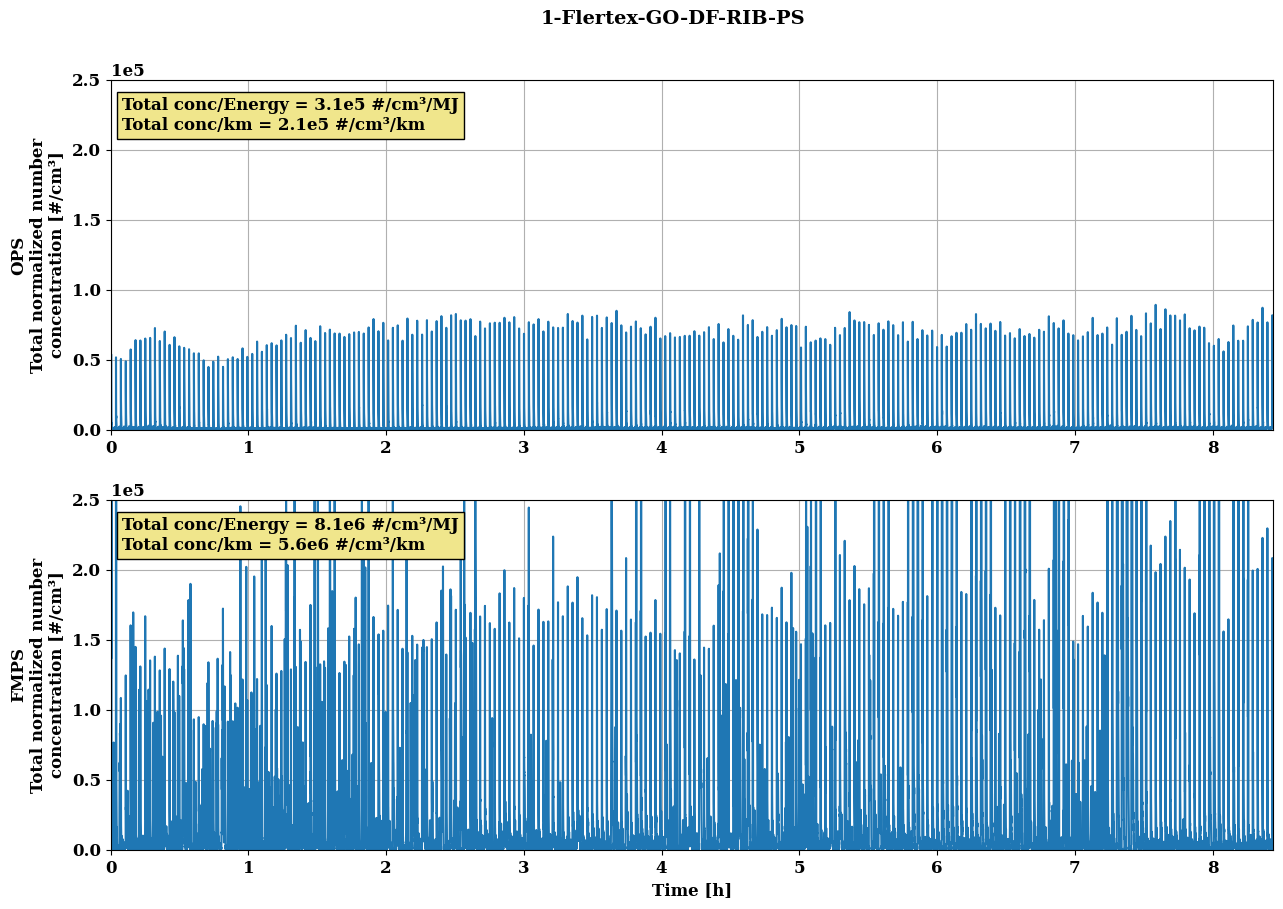

In [607]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=15,h=10)

fig.suptitle(fig_title, fontweight='bold', size=14, y=0.95) 

#TPC_OPS
ax[0].plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1),label='Total number concentration')
ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
# ax[0].set_xlim(low_limit,high_limit)
# ax[0].set_ylim(0,2.5E6)
ax[0].set_ylim(0,2.5E5)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
#ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[0].grid()

total_concentration_sum_1N = EP_OPS_out.sum(axis=1).sum(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "")
sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "")
sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "")

ax[0].text(x=0.01,y=0.95,s=sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr.sum(axis=1),label='Speed [rpm]', color='tab:blue')
ax[1].margins(x=0)
# ax[1].set_xlim(2.6,8)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
#ax[1].set_ylim(0,2.5E6)
ax[1].set_ylim(0,2.5E5)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid()

total_concentration_sum_2N = EP_FMPS_out_corr.sum(axis=1).sum(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "")
sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "")
sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "")
ax[1].text(x=0.01,y=0.95,s=sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)


(0.0, 8.438611111111111)

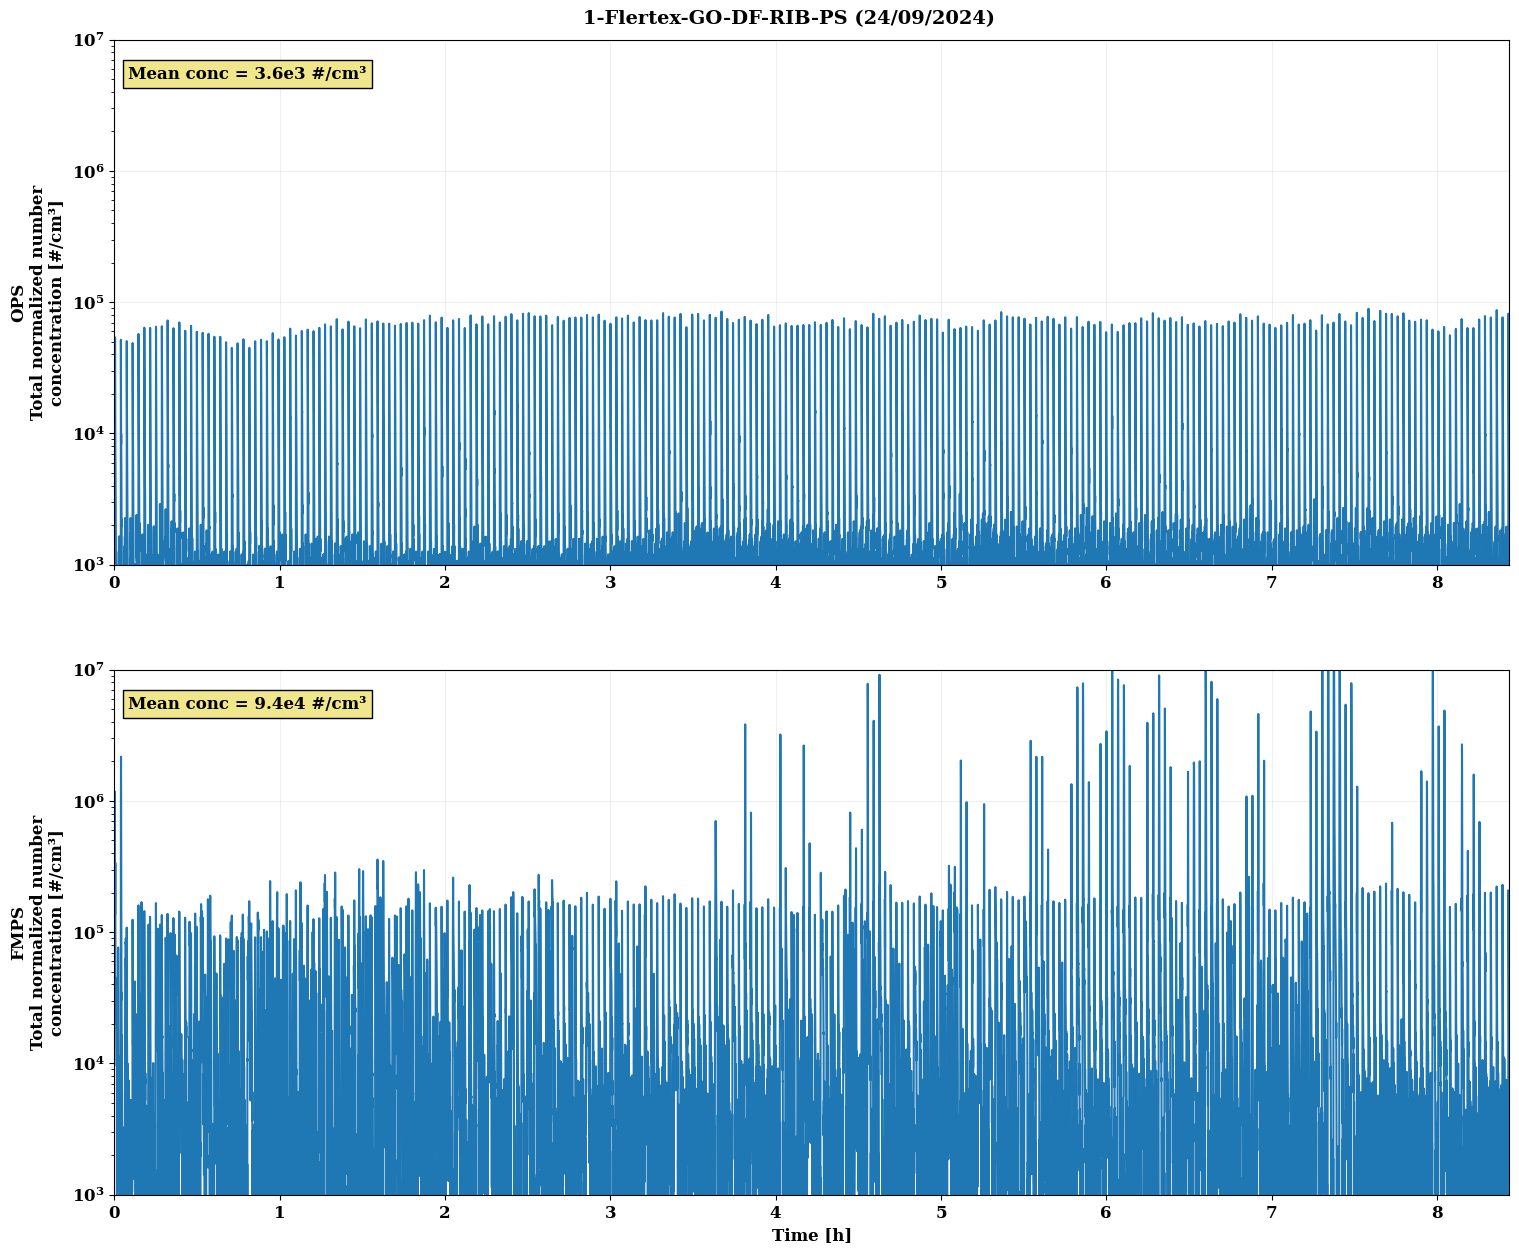

In [649]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=18,h=15)

fig.suptitle(fig_title + f" (24/09/2024)", fontweight='bold', size=14, y=0.9) 

#TPC_OPS
ax[0].plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1))
ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
ax[0].set_ylim(1e3,1e7)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[0].grid(alpha=0.2)
ax[0].set_yscale('log')

total_concentration_sum_1N = EP_OPS_out.sum(axis=1).sum(axis=0)
mean_concentration_sum_1N = EP_OPS_out.sum(axis=1).mean(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "")
mean_text_1N = f"Mean conc = {mean_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "")

ax[0].text(x=0.01,y=0.95,s=mean_text_1N,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr.sum(axis=1), color='tab:blue')
ax[1].margins(x=0)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
ax[1].set_ylim(1e3,1e7)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid(alpha=0.2)
ax[1].set_yscale('log')

total_concentration_sum_2N = EP_FMPS_out_corr.sum(axis=1).sum(axis=0)
mean_concentration_sum_2N = EP_FMPS_out_corr.sum(axis=1).mean(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "")
mean_text_2N = f"Mean conc = {mean_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "")

ax[1].text(x=0.01,y=0.95,s=mean_text_2N,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)

##### Above threshold time

(2.0125, 8.438611111111111)

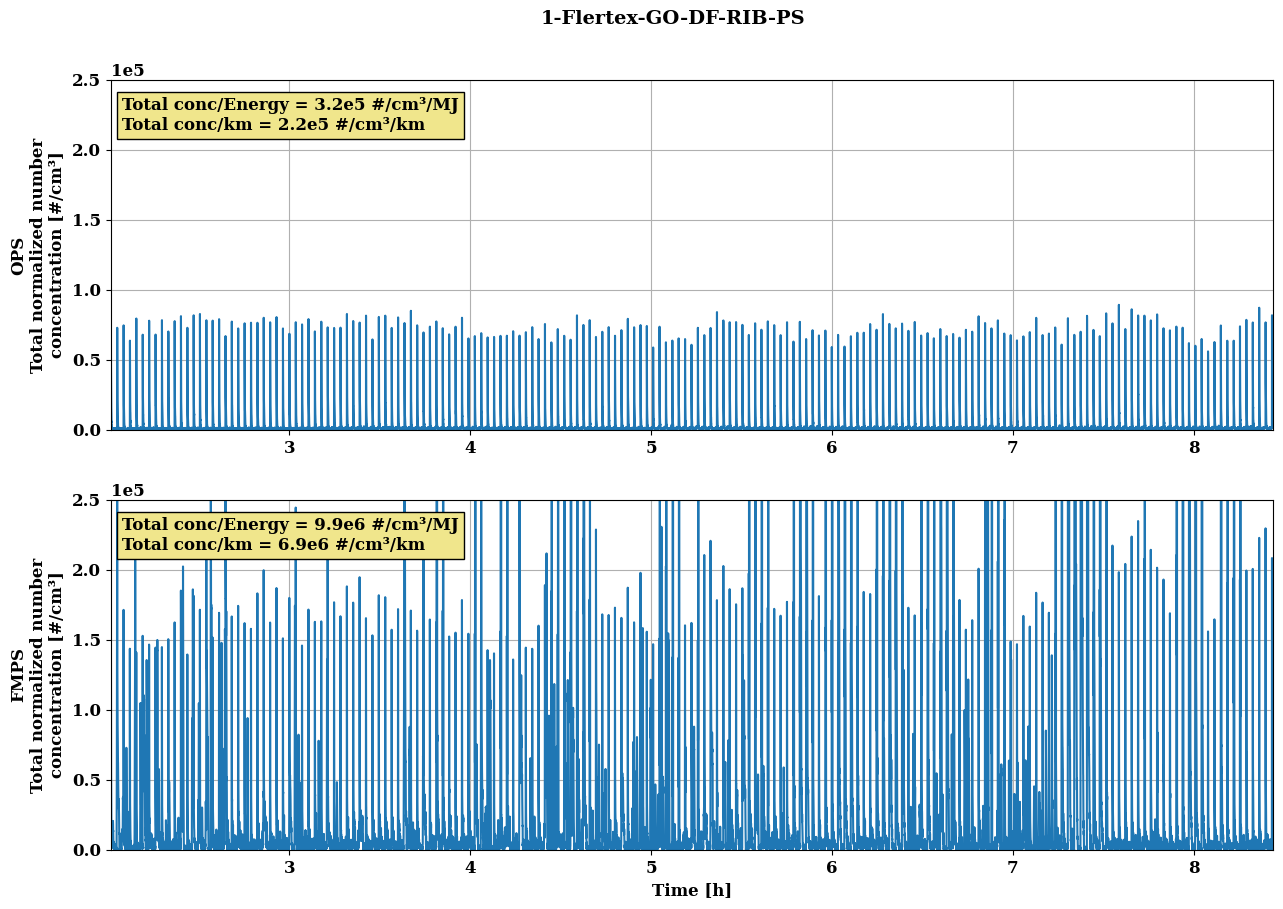

In [609]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=15,h=10)

fig.suptitle(fig_title, fontweight='bold', size=14, y=0.95) 

#TPC_OPS
ax[0].plot(EP_OPS_out_limit.index/3600,EP_OPS_out_limit.sum(axis=1),label='Total number concentration')
ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
# ax[0].set_xlim(low_limit,high_limit)
# ax[0].set_ylim(0,2.5E6)
ax[0].set_ylim(0,2.5E5)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
#ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[0].grid()

total_concentration_sum_1N = EP_OPS_out_limit.sum(axis=1).sum(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "")
sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance_limit:.1e} #/cm³/km".replace("+0", "").replace("-0", "")
sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy_limit:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "")

ax[0].text(x=0.01,y=0.95,s=sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_limit.index/3600,EP_FMPS_out_limit.sum(axis=1),label='Speed [rpm]', color='tab:blue')
ax[1].margins(x=0)
# ax[1].set_xlim(2,8.5)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
#ax[1].set_ylim(0,2.5E6)
ax[1].set_ylim(0,2.5E5)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid()

total_concentration_sum_2N = EP_FMPS_out_limit.sum(axis=1).sum(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "")
sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance_limit:.1e} #/cm³/km".replace("+0", "").replace("-0", "")
sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy_limit:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "")
ax[1].text(x=0.01,y=0.95,s=sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)


#### Plot a part of the test

In [610]:
# fig,ax = plt.subplots(nrows=3)
# fig.set_size_inches(w=15,h=10)

# fig.suptitle(fig_title, fontweight='bold', size=14, y=0.95) 

# #TPC_OPS
# ax[0].plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1),label='Total number concentration')
# ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
# ax[0].margins(x=0)
# # ax[0].set_xlim(low_limit,high_limit)
# # ax[0].set_ylim(0,2.5E6)
# ax[0].set_ylim(0,2.5E5)
# ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# #ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
# ax[0].grid()

# total_concentration_sum_1N = EP_OPS_out.sum(axis=1).sum(axis=0)
# sum_text_1N = f"Total conc= {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "")
# sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "")
# sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "")

# ax[0].text(x=0.01,y=0.95,s=sum_text_1N+'\n'+sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

# #TPC_FMPS
# ax[1].plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr.sum(axis=1),label='Speed [rpm]', color='tab:blue')
# ax[1].margins(x=0)
# ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
# # ax[1].set_ylim(0,2.5E6)
# ax[1].set_ylim(0,2.5E5)
# ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# ax[1].grid()
# ax[1].set_xlim(3.3,3.5)

# total_concentration_sum_2N = EP_FMPS_out_corr.sum(axis=1).sum(axis=0)
# sum_text_2N = f"Total conc= {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "")
# sum_text_2N_km = f"Total conc/km= {total_concentration_sum_2N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "")
# sum_text_2N_MJ = f"Total conc/Energy= {total_concentration_sum_2N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "")
# ax[1].text(x=0.01,y=0.95,s=sum_text_2N+'\n'+sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')


# ax[2].plot(VF_FMPS_out.index/3600,VF_FMPS_out['Speed [kph]'], color='tab:blue')
# ax3=ax[2].twinx()
# ax3.plot(VF_FMPS_out.index/3600,VF_FMPS_out['Force N [N]'], color='tab:orange')
# ax[2].set_xlabel('Time [h]', fontweight='bold', size=12)
# ax[2].margins(x=0, y=0)
# ax[2].set_ylabel('Speed [kph] FMPS', size = 12, color='tab:blue')
# ax3.set_ylabel('Force [N] FMPS', size = 12, color='tab:orange')

# xlim = ax[1].get_xlim()
# ax[0].set_xlim(xlim)
# ax[2].set_xlim(xlim)

### VF_FMPS vs VF_EEPS

In [611]:
# fig = plt.figure(figsize=(50,20))
# gs = gridspec.GridSpec(ncols=1, nrows=2, figure=fig)

# ax0 = fig.add_subplot(gs[0,0])
# ax2 = fig.add_subplot(gs[1,0])

# ax0.plot(VF_EEPS_in.index/3600,VF_EEPS_in['Speed [kph]'], color='tab:blue')
# ax1=ax0.twinx()
# ax1.plot(VF_EEPS_in.index/3600,VF_EEPS_in['Force N [N]'], color='tab:orange')

# ax2.plot(VF_FMPS_out.index/3600,VF_FMPS_out['Speed [kph]'], color='tab:blue')
# ax3=ax2.twinx()
# ax3.plot(VF_FMPS_out.index/3600,VF_FMPS_out['Force N [N]'], color='tab:orange')

# ax0.margins(x=0)
# ax2.margins(x=0)


# ax0.sharex(ax2)

# ax0.set_xlim(0,5.5)

# ax0.set_ylim(0,120)
# ax1.set_ylim(0,3E4)
# ax2.set_ylim(0,120)
# ax3.set_ylim(0,3E4)

# ax1.ticklabel_format(axis='y', style='sci',scilimits=(0,0))
# ax3.ticklabel_format(axis='y', style='sci',scilimits=(0,0))

# ax0.set_ylabel('Speed [kph] EEPS', size = 28, color='tab:blue')
# ax1.set_ylabel('Force [N] EEPS', size = 28, color='tab:orange')
# ax2.set_ylabel('Speed [kph] FMPS', size = 28, color='tab:blue')
# ax3.set_ylabel('Force [N] FMPS', size = 28, color='tab:orange')

# ax2.set_xlabel('Time [h]', size = 28)

# ax0.grid(alpha=0.8, axis='both')
# ax2.grid(alpha=0.8, axis='both')

# # ax0.set_xlim((t_e-500)/3600,(t_e-500)/3600)

## Inlet

In [612]:
# fig = plt.figure(figsize=(50,20))
# gs = gridspec.GridSpec(ncols=1, nrows=2, figure=fig)

# ax0 = fig.add_subplot(gs[0,0])
# ax1 = fig.add_subplot(gs[1,0])


# ax0.plot(EP_OPS_in.index/3600,EP_OPS_in.sum(axis=1), color='darkblue')
# ax1.plot(EP_EEPS_in.index/3600,EP_EEPS_in.sum(axis=1))


# ax1.margins(x=0)
# ax0.margins(x=0)
# ax0.sharex(ax1)

# ax0.set_xlim(0,4.4)
# ax0.set_ylim(0,4E4)
# ax1.set_ylim(0,3E5)

# ax0.set_ylabel('OPS \n Normalized Concentration\n [#/$cm^3$]', size= 28)
# ax1.set_ylabel('EEPS \n Normalized Concentration\n [#/$cm^3$]', size= 28)

# ax0.text(x= 0.02 ,y= 3.5E4, s='Sum = {0:.2E}'.format(EP_OPS_in.sum(axis=1).sum()), size =36)
# ax1.text(x= 0.02 ,y= 2.5E5, s='Sum = {0:.2E}'.format(EP_EEPS_in.sum(axis=1).sum()), size =36, color='darkred')

# ax0.ticklabel_format(axis='y', style='sci',scilimits=(0,0))
# ax1.ticklabel_format(axis='y', style='sci',scilimits=(0,0))


# ax1.set_xlabel('Time [h]')
# ax0.grid(alpha=0.8, axis='both')
# ax1.grid(alpha=0.8, axis='both')


## Modes

##### all

#### detection of FMPS PEAK

In [613]:
mean_peaks_corr=[]
peaks_value_corr = []

#FMPS-Cal percentile
df_FMPS_Mean_corr=EP_FMPS_out_corr.mean()
df_FMPS_Median_corr=EP_FMPS_out_corr.median()
df_FMPS_Sum_corr=EP_FMPS_out_corr.sum()

for i in range(1,len(EP_FMPS_out_corr.columns)-1):
    cond1 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i-1]
    cond2 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_corr.columns.astype(float)[i])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i])
    cond1=i==1
    cond2=df_FMPS_Mean_corr.iloc[i-1]>df_FMPS_Mean_corr.iloc[i]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_corr.columns.astype(float)[i-1])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i-1]) 

#### detection of OPS PEAK

In [614]:
mean_peaks_OPS = []
peaks_value_OPS = []

#OPS-Cal percentile
df_OPS_Mean=EP_OPS_out.mean()
df_OPS_Median=EP_OPS_out.median()
df_OPS_Sum=EP_OPS_out.sum()


for i in range(1,len(EP_OPS_out.columns)-1):
    cond1 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i-1]
    cond2 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out.columns.astype(float)[i]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i])
    cond1=i==1
    cond2=df_OPS_Mean.iloc[i-1]>df_OPS_Mean.iloc[i]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out.columns.astype(float)[i-1]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i-1])

C:\Users\Grira\AppData\Local\Temp\ipykernel_16512\4086829557.py:42: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax[0].set_ylim(0, 5e9)


Text(0.5, 0.95, '1-Flertex-GO-DF-RIB-PS')

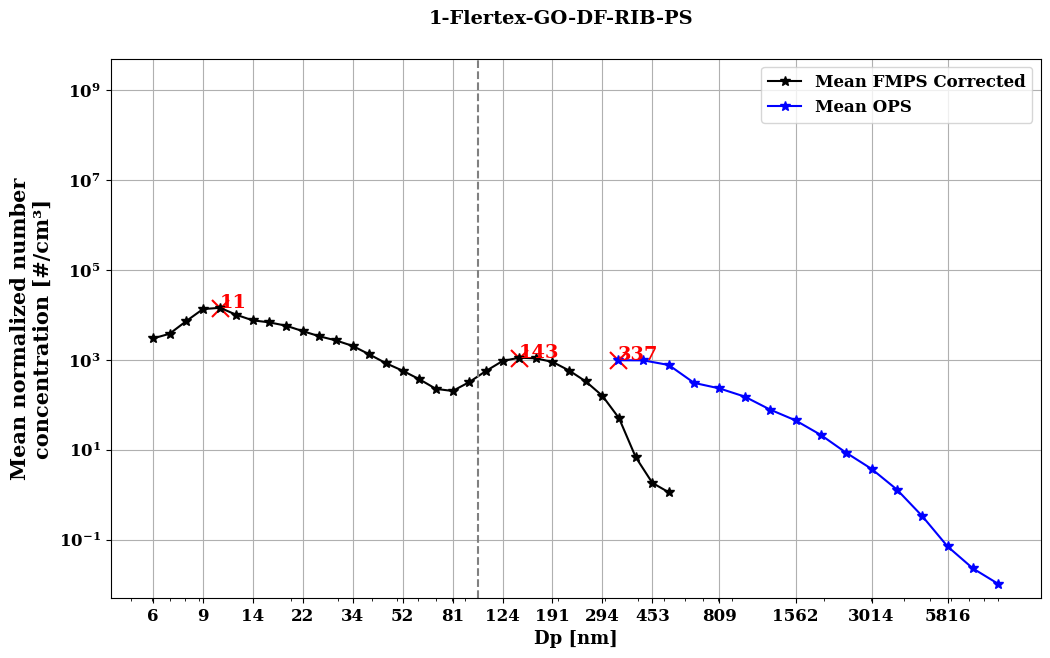

In [615]:
fig,ax = plt.subplots(nrows=1)
fig.set_size_inches(w=12,h=7)

label_EP = []
for i in range(len(EP_FMPS_out_corr.columns)):
    label_EP.append(EP_FMPS_out_corr.columns.astype(float)[i])
for i in range(3,len(EP_OPS_out.columns)):
    label_EP.append(EP_OPS_out.columns.astype(float)[i]*1000)

if not isinstance(ax, np.ndarray):
    ax = [ax]

#Plot FMPS corrected & OPS
ax[0].plot(EP_FMPS_out_corr.columns.astype(float),df_FMPS_Mean_corr, color ='k', marker='*', markersize=7, label='Mean FMPS Corrected')
ax[0].plot(EP_OPS_out.columns.astype(float)*1000,df_OPS_Mean, color ='b', marker='*', markersize=7, label='Mean OPS')
ax[0].set_ylabel('Mean normalized number\nconcentration [#/cm³]',fontweight='bold', size=15)
ax[0].scatter(mean_peaks_corr,peaks_value_corr, c='red', marker = 'x', s=150)
ax[0].scatter(mean_peaks_OPS,peaks_value_OPS, c='red', marker = 'x', s=150)

for i in range(len(mean_peaks_corr)):
    ax[0].text(mean_peaks_corr[i],peaks_value_corr[i]+math.log(20),s=round(mean_peaks_corr[i]), fontsize=14, color='red')
for i in range(len(mean_peaks_OPS)):
    ax[0].text(mean_peaks_OPS[i],peaks_value_OPS[i]+math.log(100),s=round(mean_peaks_OPS[i]), fontsize=14, color='red')

        
for axes in ax:
    #for axes in axeses:
        axes.legend(ncol=1, loc='upper right')
        axes.grid()        
        axes.set_xscale('log')
        axes.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
        axes.set_xticks(label_EP[::3])
        #axes.set_ylim(0,6000)
        # axes.set_xlim(5,9016)

ax[0].set_xlabel('Dp [nm]', fontweight='bold', size=13)
ax[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax[0].axvline(x=100, color='gray', linestyle='--')
#y-scale_Log
ax[0].set_yscale('log') 
ax[0].set_ylim(0, 5e9)  

fig.suptitle(fig_title, fontweight='bold', size=14, y=0.95) 

#fig.savefig(chemin_image)

##### Above threshold time

#### detection of FMPS PEAK

In [616]:
mean_peaks_corr=[]
peaks_value_corr = []

#FMPS-Cal percentile
df_FMPS_Mean_corr=EP_FMPS_out_limit.mean()
df_FMPS_Median_corr=EP_FMPS_out_limit.median()
df_FMPS_Sum_corr=EP_FMPS_out_limit.sum()

for i in range(1,len(EP_FMPS_out_limit.columns)-1):
    cond1 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i-1]
    cond2 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_limit.columns.astype(float)[i])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i])
    cond1=i==1
    cond2=df_FMPS_Mean_corr.iloc[i-1]>df_FMPS_Mean_corr.iloc[i]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_limit.columns.astype(float)[i-1])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i-1]) 

#### detection of OPS PEAK

In [617]:
mean_peaks_OPS = []
peaks_value_OPS = []

#OPS-Cal percentile
df_OPS_Mean=EP_OPS_out_limit.mean()
df_OPS_Median=EP_OPS_out_limit.median()
df_OPS_Sum=EP_OPS_out_limit.sum()


for i in range(1,len(EP_OPS_out_limit.columns)-1):
    cond1 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i-1]
    cond2 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_limit.columns.astype(float)[i]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i])
    cond1=i==1
    cond2=df_OPS_Mean.iloc[i-1]>df_OPS_Mean.iloc[i]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_limit.columns.astype(float)[i-1]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i-1])

Text(0.5, 0.95, '1-Flertex-GO-DF-RIB-PS')

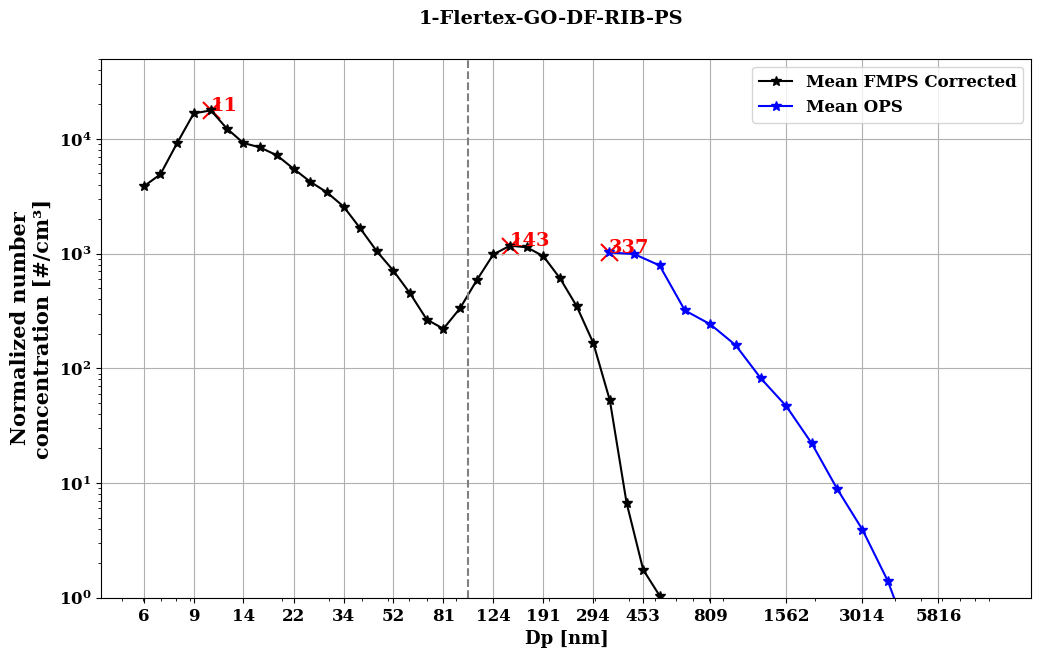

In [618]:
fig,ax = plt.subplots(nrows=1)
fig.set_size_inches(w=12,h=7)

label_EP = []
for i in range(len(EP_FMPS_out_limit.columns)):
    label_EP.append(EP_FMPS_out_limit.columns.astype(float)[i])
for i in range(3,len(EP_OPS_out_limit.columns)):
    label_EP.append(EP_OPS_out_limit.columns.astype(float)[i]*1000)

if not isinstance(ax, np.ndarray):
    ax = [ax]

#Plot FMPS corrected & OPS
ax[0].plot(EP_FMPS_out_limit.columns.astype(float),df_FMPS_Mean_corr, color ='k', marker='*', markersize=7, label='Mean FMPS Corrected')
ax[0].plot(EP_OPS_out_limit.columns.astype(float)*1000,df_OPS_Mean, color ='b', marker='*', markersize=7, label='Mean OPS')
ax[0].set_ylabel('Normalized number\nconcentration [#/cm³]',fontweight='bold', size=15)
ax[0].scatter(mean_peaks_corr,peaks_value_corr, c='red', marker = 'x', s=150)
ax[0].scatter(mean_peaks_OPS,peaks_value_OPS, c='red', marker = 'x', s=150)

for i in range(len(mean_peaks_corr)):
    ax[0].text(mean_peaks_corr[i],peaks_value_corr[i]+math.log(20),s=round(mean_peaks_corr[i]), fontsize=14, color='red')
for i in range(len(mean_peaks_OPS)):
    ax[0].text(mean_peaks_OPS[i],peaks_value_OPS[i]+math.log(100),s=round(mean_peaks_OPS[i]), fontsize=14, color='red')

        
for axes in ax:
    #for axes in axeses:
        axes.legend(ncol=1, loc='upper right')
        axes.grid()        
        axes.set_xscale('log')
        axes.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
        axes.set_xticks(label_EP[::3])
        #axes.set_ylim(0,6000)
        # axes.set_xlim(5,9016)

ax[0].set_xlabel('Dp [nm]', fontweight='bold', size=13)
ax[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))

#y-scale_Log
ax[0].set_yscale('log') 
ax[0].set_ylim(1, 5e4)  
ax[0].axvline(x=100, color='gray', linestyle='--')

fig.suptitle(fig_title, fontweight='bold', size=14, y=0.95) 

#fig.savefig(chemin_image)

### Calculation of the mean PM concentrations 

#### Plot to check that braking separation is good

In [619]:
# fig,ax = plt.subplots()
# fig.set_size_inches(w=15,h=7)

# ax.plot(EP_FMPS_out_corr.index,EP_FMPS_out_corr.sum(axis=1))
# ax.axvline(x= df_brakings['Start'].iloc[20], color='k', ls='--')
# ax.axvline(x= df_brakings['End'].iloc[20], color='k', ls='--')

# ax.set_xlim(df_brakings['Start'].iloc[20]-5,df_brakings['End'].iloc[20]+5)
# ax.set_ylim(0,1E6)

#### All

#### FMPS

In [620]:
# df_summed = pd.DataFrame(columns=EP_FMPS_out_corr.columns)

# for i in range(len(df_brakings)):
#     d = EP_FMPS_out_corr.iloc[int(df_brakings['Start'].iloc[i]):int(df_brakings['End'].iloc[i])]
#     df_summed.loc[len(df_summed)] = d.sum()

# df_summed['Total'] = df_summed.sum(axis=1)

# mean = df_summed['Total'].mean()
# std = df_summed['Total'].std()

# # print(f'Mean_FMPS ± STD_FMPS: {mean:.2E}',"±", f'{std:.2E}')
# print(f'Mean_Nb_FMPS : {mean:.2E}')
# print(f'STD_Nb_FMPS : {std:.2E}')
# print(f'SEM_Nb_FMPS : {std/np.sqrt(len(df_brakings)):.2E}')

#### OPS

In [621]:
# df_summed_OPS = pd.DataFrame(columns=EP_OPS_out.columns)

# for i in range(len(df_brakings)):
#     d = EP_OPS_out.iloc[int(df_brakings['Start'].iloc[i]):int(df_brakings['End'].iloc[i])]
#     df_summed_OPS.loc[len(df_summed_OPS)] = d.sum()

# df_summed_OPS['Total'] = df_summed_OPS.sum(axis=1)

# mean = df_summed_OPS['Total'].mean()
# std = df_summed_OPS['Total'].std()

# # print(f'Mean_OPS ± STD_OPS: {mean:.2E}',"±", f'{std:.2E}')
# print(f'Mean_Nb_OPS : {mean:.2E}')
# print(f'STD_Nb_OPS : {std:.2E}')
# print(f'SEM_Nb_OPS : {std/np.sqrt(len(df_brakings)):.2E}')

#### Above threshold time

#### FMPS

In [622]:
# df_summed_limit = pd.DataFrame(columns=EP_FMPS_out_limit.columns)

# for i in range(len(df_brakings_limit)):
#     d = EP_FMPS_out_limit.iloc[int(df_brakings_limit['Start'].iloc[i]):int(df_brakings_limit['End'].iloc[i])]
#     df_summed_limit.loc[len(df_summed_limit)] = d.sum()

# df_summed_limit['Total'] = df_summed_limit.sum(axis=1)

# mean = df_summed_limit['Total'].mean()
# std = df_summed_limit['Total'].std()

# print(f'Mean_Nb_FMPS : {mean:.2E}')
# print(f'STD_Nb_FMPS : {std:.2E}') #STD: Spread of individual data points around the mean -> Describes the variability of data
# print(f'SEM_Nb_FMPS : {std/np.sqrt(len(df_brakings_limit)):.2E}') #Uncertainty in the mean estimate -> Shows how precise the mean 

#### OPS

###### Without interbraking

In [623]:
df_summed_OPS_limit = pd.DataFrame(columns=EP_OPS_out_limit.columns)

for i in range(len(df_brakings_limit)):
    d = EP_OPS_out_limit.iloc[int(df_brakings_limit['Start'].iloc[i]):int(df_brakings_limit['End'].iloc[i])]
    df_summed_OPS_limit.loc[len(df_summed_OPS_limit)] = d.sum()

df_summed_OPS_limit['Total'] = df_summed_OPS_limit.sum(axis=1)

mean = df_summed_OPS_limit['Total'].mean()
std = df_summed_OPS_limit['Total'].std()

print(f'Mean_Nb_OPS : {mean:.2E}')
print(f'STD_Nb_OPS : {std:.2E}')
print(f'SEM_Nb_OPS : {std/np.sqrt(len(df_brakings_limit)):.2E}')

Mean_Nb_OPS : 1.80E+05
STD_Nb_OPS : 1.60E+05
SEM_Nb_OPS : 1.18E+04


###### With interbraking

In [624]:
df_summed_OPS_limit = pd.DataFrame(columns=EP_OPS_out_limit.columns)

for i in range(len(df_brakings_limit)-1):
    d = EP_OPS_out_limit.iloc[int(df_brakings_limit['Start'].iloc[i]):int(df_brakings_limit['Start'].iloc[i+1])]
    df_summed_OPS_limit.loc[len(df_summed_OPS_limit)] = d.sum()

df_summed_OPS_limit['Total'] = df_summed_OPS_limit.sum(axis=1)

mean = df_summed_OPS_limit['Total'].mean()
std = df_summed_OPS_limit['Total'].std()

print(f'Mean_Nb_OPS : {mean:.2E}')
print(f'STD_Nb_OPS : {std:.2E}')
print(f'SEM_Nb_OPS : {std/np.sqrt(len(df_brakings_limit)):.2E}')

Mean_Nb_OPS : 3.18E+05
STD_Nb_OPS : 2.17E+05
SEM_Nb_OPS : 1.60E+04


###### Mean of interbraking

In [625]:
df_summed_OPS_limit = pd.DataFrame(columns=EP_OPS_out_limit.columns)

for i in range(len(df_brakings_limit)-1):
    d = EP_OPS_out_limit.iloc[int(df_brakings_limit['End'].iloc[i]):int(df_brakings_limit['Start'].iloc[i+1])]
    df_summed_OPS_limit.loc[len(df_summed_OPS_limit)] = d.sum()

df_summed_OPS_limit['Total'] = df_summed_OPS_limit.sum(axis=1)

mean = df_summed_OPS_limit['Total'].mean()
std = df_summed_OPS_limit['Total'].std()

print(f'Mean_Nb_OPS : {mean:.2E}')
print(f'STD_Nb_OPS : {std:.2E}')
print(f'SEM_Nb_OPS : {std/np.sqrt(len(df_brakings_limit)):.2E}')

Mean_Nb_OPS : 1.37E+05
STD_Nb_OPS : 1.35E+05
SEM_Nb_OPS : 9.96E+03


# Data only FMPS Dp >= 100 nm

#### inlet

In [626]:
# fig = plt.figure(figsize=(50,20))
# gs = gridspec.GridSpec(ncols=1, nrows=2, figure=fig)

# ax0 = fig.add_subplot(gs[0,0])
# ax1 = fig.add_subplot(gs[1,0])


# ax0.plot(EP_OPS_in.index/3600,EP_OPS_in.sum(axis=1), color='darkblue')
# ax1.plot(EP_EEPS_in.index/3600,EP_EEPS_in[EP_EEPS_in.columns[20:]].sum(axis=1))

# ax1.margins(x=0)
# ax0.margins(x=0)
# ax0.sharex(ax1)


# ax0.set_ylabel('OPS \n Normalized Concentration\n [#/$cm^3$]', size= 28)
# ax1.set_ylabel('EEPS \n Normalized Concentration\n [#/$cm^3$]', size= 28)

# ax0.text(x= 0.05 ,y= 900, s='Sum = {0:.2E}'.format(EP_OPS_in.sum(axis=1).sum()), size =36 )
# ax1.text(x= 0.05 ,y= 900000, s='Sum = {0:.2E}'.format(EP_EEPS_in[EP_EEPS_in.columns[20:]].sum(axis=1).sum()), size =36, color='darkred' )


# ax0.ticklabel_format(axis='y', style='sci',scilimits=(0,0))
# ax1.ticklabel_format(axis='y', style='sci',scilimits=(0,0))

# ax1.set_xlabel('Time [h]')

# ax0.set_ylim(0,1E3)
# ax1.set_ylim(0,1E6)


# ax0.grid(alpha=0.8, axis='both')
# ax1.grid(alpha=0.8, axis='both')


#### outlet

In [627]:
# fig = plt.figure(figsize=(50,40))
# gs = gridspec.GridSpec(ncols=1, nrows=4, figure=fig)

# ax0 = fig.add_subplot(gs[0,0])
# ax1 = fig.add_subplot(gs[1,0])
# ax2 = fig.add_subplot(gs[2,0])
# ax3 = fig.add_subplot(gs[3,0])

# ax0.plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1), color='darkblue')
# ax1.plot(EP_FMPS_out.index/3600,EP_FMPS_out[EP_FMPS_out.columns[20:]].sum(axis=1))
# ax2.plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1))
# ax3.plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1))

# ax0.margins(x=0)
# ax1.margins(x=0)
# ax2.margins(x=0)
# ax3.margins(x=0)
# ax0.sharex(ax1)
# ax2.sharex(ax1)
# ax3.sharex(ax1)

# ax1.margins(x=0)

# ax0.set_ylim(0,1E3)
# ax1.set_ylim(0,1E6)
# # ax1.set_yscale('log')
# # ax1.set_ylim(1E3,5E7)

# ax2.set_yscale('log')
# ax2.set_ylim(1E3,5E7)

# ax3.set_ylim(0,5E5)

# ax0.text(x= 0.05 ,y= 900, s='Sum = {0:.2E}'.format(EP_OPS_out.sum(axis=1).sum()), size=36)
# ax1.text(x= 0.05 ,y= 900000, s='Sum = {0:.2E}'.format(EP_FMPS_out[EP_FMPS_out.columns[20:]].sum(axis=1).sum()), size=36)
# #ax1.text(x= 0.05 ,y= 1E7, s='Sum = {0:.2E}'.format(EP_FMPS_out[EP_FMPS_out.columns[20:]].sum(axis=1).sum()), size=36)
# ax3.text(x= 0.05 ,y= 450000, s='Sum = {0:.2E}'.format(EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1).sum()), size=36)
# ax0.ticklabel_format(axis='y', style='sci',scilimits=(0,0))
# ax3.ticklabel_format(axis='y', style='sci',scilimits=(0,0))


# ax0.set_ylabel('OPS \n Normalized Concentration\n [#/$cm^3$]', size = 28)
# ax1.set_ylabel('FMPS \n Normalized Concentration\n [#/$cm^3$]', size = 28)
# ax2.set_ylabel('FMPS \n Corrected Normalized Concentration\n [#/$cm^3$]', size = 28)
# ax3.set_ylabel('FMPS \n Corrected Normalized Concentration\n [#/$cm^3$]', size = 28)

# ax3.set_xlabel('Time [h]')

# ax0.grid(alpha=0.8, axis='both')
# ax1.grid(alpha=0.8, axis='both')
# ax2.grid(alpha=0.8, axis='both')
# ax3.grid(alpha=0.8, axis='both')

#### all

##### Normalized number

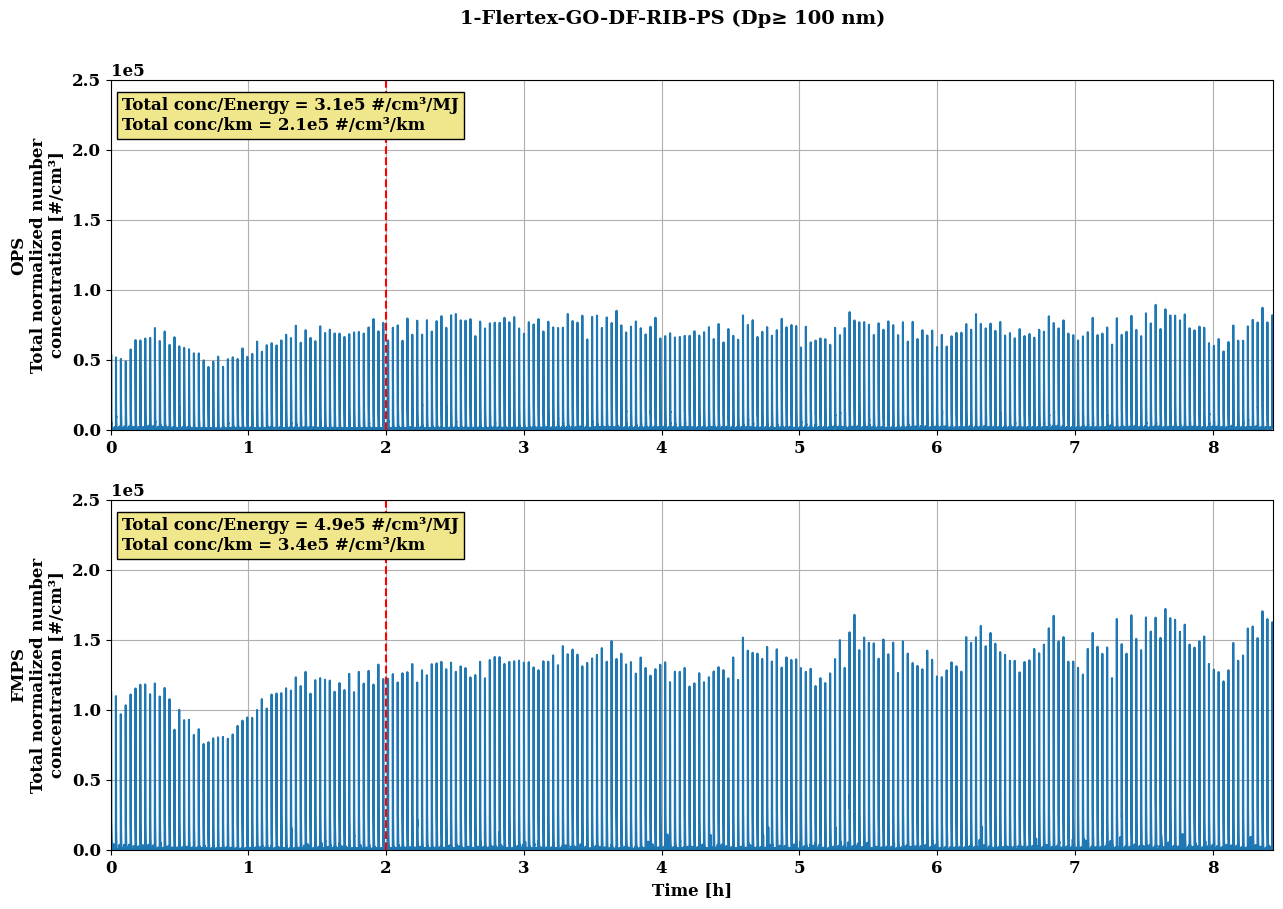

In [628]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=15,h=10)

fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#TPC_OPS
ax[0].plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1),label='Total number concentration')
ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
# ax[0].set_xlim(low_limit,high_limit)
# ax[0].set_ylim(0,2.5E6)
ax[0].set_ylim(0,2.5E5)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
#ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[0].grid()

total_concentration_sum_1N = EP_OPS_out.sum(axis=1).sum(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "-")
sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "-")

# ax[0].text(x=0.01,y=0.95,s=sum_text_1N+'\n'+sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')
ax[0].text(x=0.01,y=0.95,s=sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_corr.index/3600,EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1),label='Speed [rpm]', color='tab:blue')
ax[1].margins(x=0)
# ax[1].set_xlim(low_limit,high_limit)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
# ax[1].set_ylim(0,2.5E6)
ax[1].set_ylim(0,2.5E5)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid()

total_concentration_sum_2N = EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1).sum(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "-")
sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "-")
# ax[1].text(x=0.01,y=0.95,s=sum_text_2N+'\n'+sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')
ax[1].text(x=0.01,y=0.95,s=sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)
ax[0].axvline(x=threshold/3600, color='red', linestyle='--')
ax[1].axvline(x=threshold/3600, color='red', linestyle='--')


##### Modes

In [629]:
mean_peaks_corr=[]
peaks_value_corr = []

#FMPS-Cal percentile
df_FMPS_Mean_corr=EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].mean()
df_FMPS_Median_corr=EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].median()
df_FMPS_Sum_corr=EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum()
df_FMPS_10th_corr=EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].quantile(q=0.1)
df_FMPS_90th_corr=EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].quantile(q=0.9)

for i in range(1,len(EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].columns)-1):
    cond1 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i-1]
    cond2 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].columns.astype(float)[i])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i])
    cond1=i==1
    cond2=df_FMPS_Mean_corr.iloc[i-1]>df_FMPS_Mean_corr.iloc[i]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].columns.astype(float)[i-1])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i-1]) 

In [630]:
mean_peaks_OPS = []
peaks_value_OPS = []

#OPS-Cal percentile
df_OPS_Mean=EP_OPS_out.mean()
df_OPS_Median=EP_OPS_out.median()
df_OPS_Sum=EP_OPS_out.sum()


for i in range(1,len(EP_OPS_out.columns)-1):
    cond1 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i-1]
    cond2 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out.columns.astype(float)[i]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i])
    cond1=i==1
    cond2=df_OPS_Mean.iloc[i-1]>df_OPS_Mean.iloc[i]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out.columns.astype(float)[i-1]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i-1])

Text(0.5, 0.95, '1-Flertex-GO-DF-RIB-PS (Dp≥ 100 nm)')

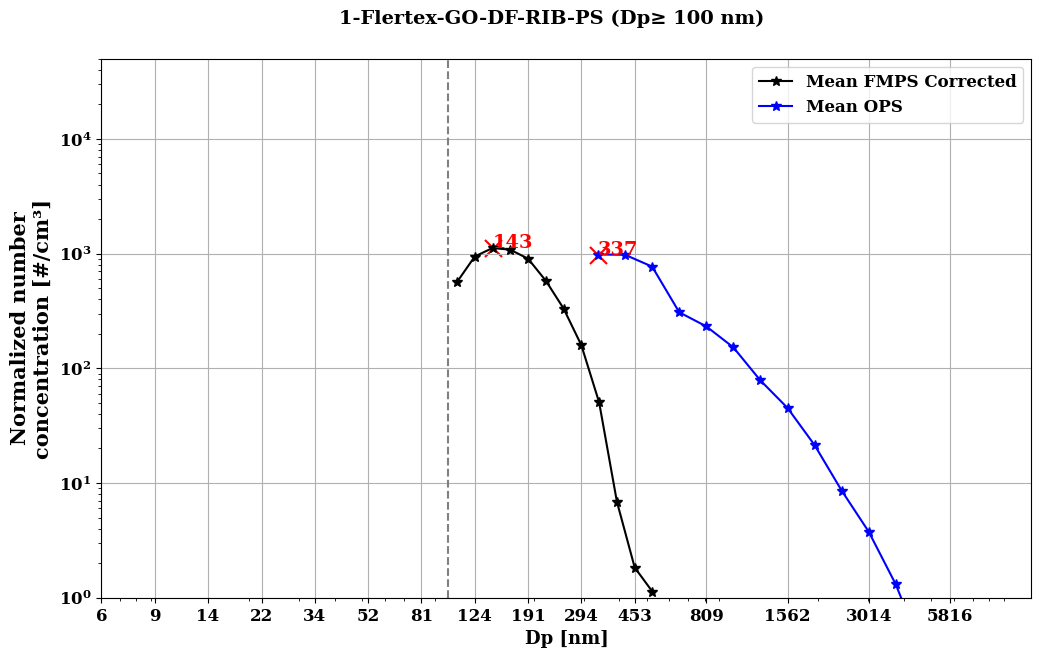

In [631]:
fig,ax = plt.subplots(nrows=1)
fig.set_size_inches(w=12,h=7)

label_EP = []
for i in range(len(EP_FMPS_out_corr.columns)):
    label_EP.append(EP_FMPS_out_corr.columns.astype(float)[i])
for i in range(3,len(EP_OPS_out.columns)):
    label_EP.append(EP_OPS_out_limit.columns.astype(float)[i]*1000)

if not isinstance(ax, np.ndarray):
    ax = [ax]

#Plot FMPS corrected & OPS
ax[0].plot(EP_FMPS_out_corr.columns[20:].astype(float),df_FMPS_Mean_corr, color ='k', marker='*', markersize=7, label='Mean FMPS Corrected')
ax[0].plot(EP_OPS_out.columns.astype(float)*1000,df_OPS_Mean, color ='b', marker='*', markersize=7, label='Mean OPS')
ax[0].set_ylabel('Normalized number\nconcentration [#/cm³]',fontweight='bold', size=15)
ax[0].scatter(mean_peaks_corr,peaks_value_corr, c='red', marker = 'x', s=150)
ax[0].scatter(mean_peaks_OPS,peaks_value_OPS, c='red', marker = 'x', s=150)

for i in range(len(mean_peaks_corr)):
    ax[0].text(mean_peaks_corr[i],peaks_value_corr[i]+math.log(20),s=round(mean_peaks_corr[i]), fontsize=14, color='red')
for i in range(len(mean_peaks_OPS)):
    ax[0].text(mean_peaks_OPS[i],peaks_value_OPS[i]+math.log(100),s=round(mean_peaks_OPS[i]), fontsize=14, color='red')


for axes in ax:
    #for axes in axeses:
        axes.legend(ncol=1, loc='upper right')
        axes.grid()        
        axes.set_xscale('log')
        axes.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
        axes.set_xticks(label_EP[::3])
        #axes.set_ylim(0,6000)
        # axes.set_xlim(5,9016)

ax[0].set_xlabel('Dp [nm]', fontweight='bold', size=13)
#ax[0].set_ylim(0,6500)
ax[0].set_ylim(0,14000)

ax[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax[0].axvline(x=100, color='gray', linestyle='--')
#y-scale_Log
ax[0].set_yscale('log') 
ax[0].set_ylim(1, 5e4)  
fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#fig.savefig(chemin_image)

#### Above threshold time

##### Normalized number

(2.0125, 8.438611111111111)

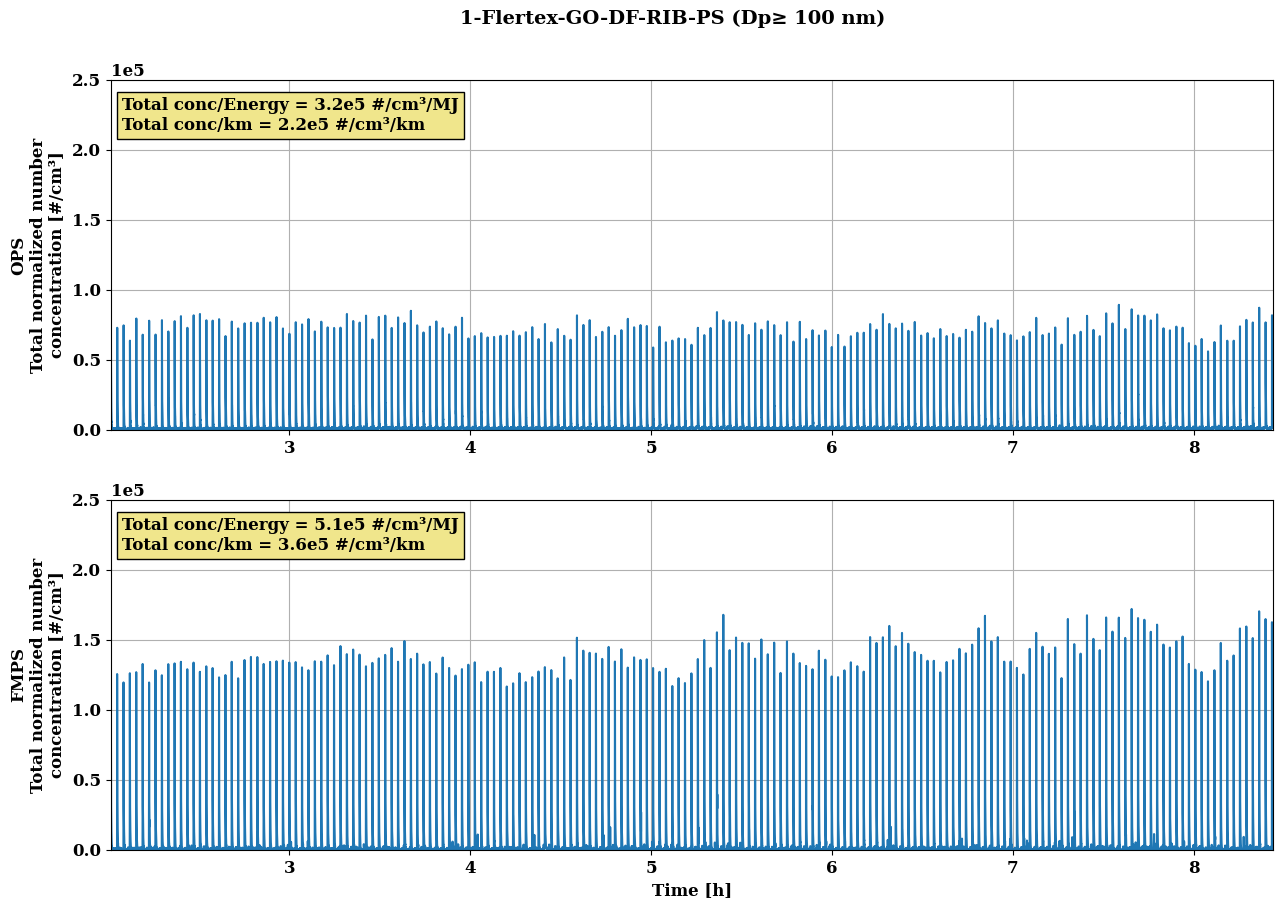

In [632]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=15,h=10)

fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#TPC_OPS
ax[0].plot(EP_OPS_out_limit.index/3600,EP_OPS_out_limit.sum(axis=1),label='Total number concentration')
ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
# ax[0].set_xlim(low_limit,high_limit)
# ax[0].set_ylim(0,2.5E6)
ax[0].set_ylim(0,2.5E5)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
#ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[0].grid()

total_concentration_sum_1N = EP_OPS_out_limit.sum(axis=1).sum(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "-")
sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance_limit:.1e} #/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy_limit:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "-")

ax[0].text(x=0.01,y=0.95,s=sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_limit.index/3600,EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].sum(axis=1),label='Speed [rpm]', color='tab:blue')
ax[1].margins(x=0)
# ax[1].set_xlim(low_limit,high_limit)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
# ax[1].set_ylim(0,2.5E6)
ax[1].set_ylim(0,2.5E5)
# ax[1].set_xlim(5,5.5)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid()

total_concentration_sum_2N = EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].sum(axis=1).sum(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "-")
sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance_limit:.1e} #/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy_limit:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "-")
ax[1].text(x=0.01,y=0.95,s=sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)

In [633]:
# fig,ax = plt.subplots(nrows=3)
# fig.set_size_inches(w=15,h=10)

# fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

# #TPC_OPS
# ax[0].plot(EP_OPS_out.index/3600,EP_OPS_out.sum(axis=1),label='Total number concentration')
# ax[0].set_ylabel('OPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
# ax[0].margins(x=0)
# # ax[0].set_xlim(low_limit,high_limit)
# # ax[0].set_ylim(0,2.5E6)
# ax[0].set_ylim(0,2.5E5)
# ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# #ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
# ax[0].grid()

# total_concentration_sum_1N = EP_OPS_out.sum(axis=1).sum(axis=0)
# sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} #/cm³".replace("+0", "").replace("-0", "-")
# sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "-")
# sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "-")
# # ax[0].text(x=0.01,y=0.95,s=sum_text_1N+'\n'+sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

# #TPC_FMPS
# ax[1].plot(EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].index/3600,EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1),label='Speed [rpm]', color='tab:blue')
# ax[1].margins(x=0)
# ax[1].set_ylabel('FMPS\nTotal normalized number\nconcentration [#/cm³]', fontweight='bold', size=12)
# # ax[1].set_ylim(0,2.5E6)
# ax[1].set_ylim(0,2.5E5)
# ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
# ax[1].grid()
# ax[1].set_xlim(2,8.45)

# total_concentration_sum_2N = EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].sum(axis=1).sum(axis=0)
# sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} #/cm³".replace("+0", "").replace("-0", "-")
# sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance:.1e} #/cm³/km".replace("+0", "").replace("-0", "-")
# sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy:.1e} #/cm³/MJ".replace("+0", "").replace("-0", "-")
# # ax[1].text(x=0.01,y=0.95,s=sum_text_2N+'\n'+sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')


# ax[2].plot(VF_FMPS_out.index/3600,VF_FMPS_out['Speed [kph]'], color='tab:blue')
# ax3=ax[2].twinx()
# ax3.plot(VF_FMPS_out.index/3600,VF_FMPS_out['Force N [N]'], color='tab:orange')
# ax[2].set_xlabel('Time [h]', fontweight='bold', size=12)
# ax[2].margins(x=0, y=0)
# ax[2].set_ylabel('Speed [kph] FMPS', size = 12, color='tab:blue')
# ax3.set_ylabel('Force [N] FMPS', size = 12, color='tab:orange')

# xlim = ax[1].get_xlim()
# ax[0].set_xlim(xlim)
# ax[2].set_xlim(xlim)

##### Modes

In [634]:
mean_peaks_corr=[]
peaks_value_corr = []

#FMPS-Cal percentile
df_FMPS_Mean_corr=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].mean()
df_FMPS_Median_corr=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].median()
df_FMPS_Sum_corr=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].sum()
df_FMPS_10th_corr=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].quantile(q=0.1)
df_FMPS_90th_corr=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].quantile(q=0.9)

for i in range(1,len(EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].columns)-1):
    cond1 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i-1]
    cond2 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].columns.astype(float)[i])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i])
    cond1=i==1
    cond2=df_FMPS_Mean_corr.iloc[i-1]>df_FMPS_Mean_corr.iloc[i]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].columns.astype(float)[i-1])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i-1]) 

In [635]:
mean_peaks_OPS = []
peaks_value_OPS = []

#OPS-Cal percentile
df_OPS_Mean=EP_OPS_out_limit.mean()
df_OPS_Median=EP_OPS_out_limit.median()
df_OPS_Sum=EP_OPS_out_limit.sum()


for i in range(1,len(EP_OPS_out_limit.columns)-1):
    cond1 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i-1]
    cond2 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_limit.columns.astype(float)[i]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i])
    cond1=i==1
    cond2=df_OPS_Mean.iloc[i-1]>df_OPS_Mean.iloc[i]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_limit.columns.astype(float)[i-1]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i-1])

Text(0.5, 0.95, '1-Flertex-GO-DF-RIB-PS (Dp≥ 100 nm)')

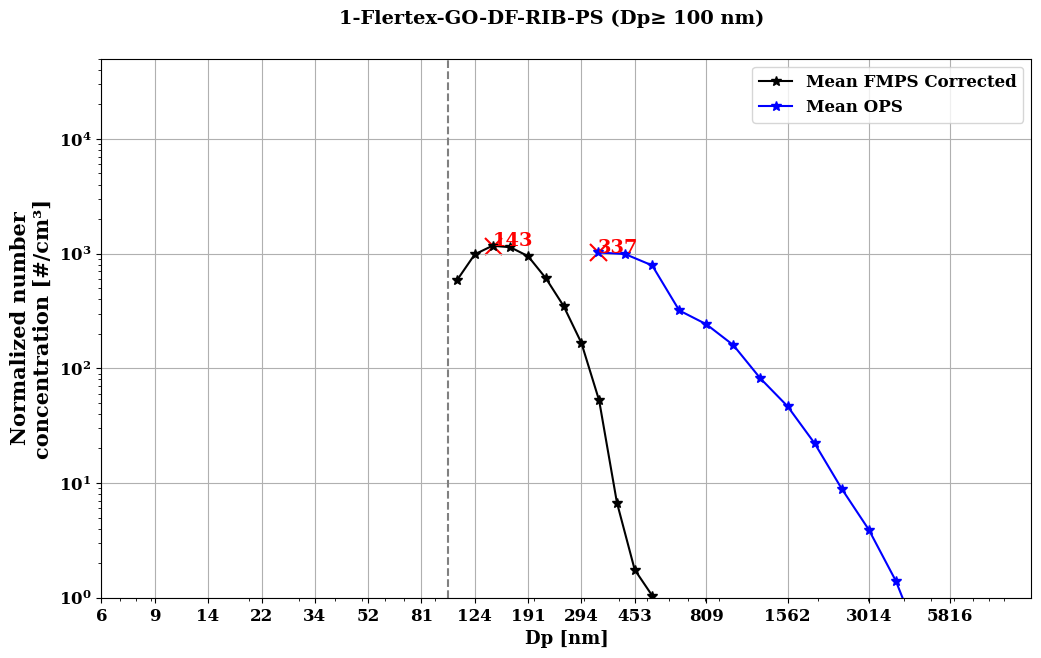

In [636]:
fig,ax = plt.subplots(nrows=1)
fig.set_size_inches(w=12,h=7)

label_EP = []
for i in range(len(EP_FMPS_out_limit.columns)):
    label_EP.append(EP_FMPS_out_limit.columns.astype(float)[i])
for i in range(3,len(EP_OPS_out_limit.columns)):
    label_EP.append(EP_OPS_out_limit.columns.astype(float)[i]*1000)

if not isinstance(ax, np.ndarray):
    ax = [ax]

#Plot FMPS corrected & OPS
ax[0].plot(EP_FMPS_out_limit.columns[20:].astype(float),df_FMPS_Mean_corr, color ='k', marker='*', markersize=7, label='Mean FMPS Corrected')
ax[0].plot(EP_OPS_out_limit.columns.astype(float)*1000,df_OPS_Mean, color ='b', marker='*', markersize=7, label='Mean OPS')
ax[0].set_ylabel('Normalized number\nconcentration [#/cm³]',fontweight='bold', size=15)
ax[0].scatter(mean_peaks_corr,peaks_value_corr, c='red', marker = 'x', s=150)
ax[0].scatter(mean_peaks_OPS,peaks_value_OPS, c='red', marker = 'x', s=150)

for i in range(len(mean_peaks_corr)):
    ax[0].text(mean_peaks_corr[i],peaks_value_corr[i]+math.log(20),s=round(mean_peaks_corr[i]), fontsize=14, color='red')
for i in range(len(mean_peaks_OPS)):
    ax[0].text(mean_peaks_OPS[i],peaks_value_OPS[i]+math.log(100),s=round(mean_peaks_OPS[i]), fontsize=14, color='red')


for axes in ax:
    #for axes in axeses:
        axes.legend(ncol=1, loc='upper right')
        axes.grid()        
        axes.set_xscale('log')
        axes.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
        axes.set_xticks(label_EP[::3])
        #axes.set_ylim(0,6000)
        # axes.set_xlim(5,9016)

ax[0].set_xlabel('Dp [nm]', fontweight='bold', size=13)
#ax[0].set_ylim(0,6500)
ax[0].set_ylim(0,14000)

ax[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax[0].axvline(x=100, color='gray', linestyle='--')
#y-scale_Log
ax[0].set_yscale('log') 
ax[0].set_ylim(1, 5e4)  
fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#fig.savefig(chemin_image)

### FMPS Calculation of the mean of all total PM concentrations and uncertainties

#### All

##### FMPS 

In [637]:
# df_summed_limit = pd.DataFrame(columns=EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].columns)

# for i in range(len(df_brakings)):
#     d = EP_FMPS_out_corr[EP_FMPS_out_corr.columns[20:]].iloc[int(df_brakings['Start'].iloc[i]):int(df_brakings['End'].iloc[i])]
#     df_summed_limit.loc[len(df_summed_limit)] = d.sum()

# df_summed_limit['Total'] = df_summed_limit.sum(axis=1)

# mean = df_summed_limit['Total'].mean()
# std = df_summed_limit['Total'].std()

# print(f'Mean_Nb_FMPS : {mean:.2E}')
# print(f'STD_Nb_FMPS : {std:.2E}')
# print(f'SEM_Nb_FMPS : {std/np.sqrt(len(df_brakings)):.2E}')

#### Above threshold time

##### FMPS 

###### Without interbraking

In [638]:
df_summed_limit = pd.DataFrame(columns=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].columns)

for i in range(len(df_brakings_limit)):
    d = EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].iloc[int(df_brakings_limit['Start'].iloc[i]):int(df_brakings_limit['End'].iloc[i])]
    df_summed_limit.loc[len(df_summed_limit)] = d.sum()

df_summed_limit['Total'] = df_summed_limit.sum(axis=1)

mean = df_summed_limit['Total'].mean()
std = df_summed_limit['Total'].std()

print(f'Mean_Nb_FMPS : {mean:.2E}')
print(f'STD_Nb_FMPS : {std:.2E}')
print(f'SEM_Nb_FMPS : {std/np.sqrt(len(df_brakings_limit)):.2E}')

Mean_Nb_FMPS : 2.99E+05
STD_Nb_FMPS : 2.95E+05
SEM_Nb_FMPS : 2.18E+04


###### With interbraking

In [639]:
df_summed_limit = pd.DataFrame(columns=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].columns)

for i in range(len(df_brakings_limit)-1):
    d = EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].iloc[int(df_brakings_limit['Start'].iloc[i]):int(df_brakings_limit['Start'].iloc[i+1])]
    df_summed_limit.loc[len(df_summed_limit)] = d.sum()

df_summed_limit['Total'] = df_summed_limit.sum(axis=1)

mean = df_summed_limit['Total'].mean()
std = df_summed_limit['Total'].std()

print(f'Mean_Nb_FMPS : {mean:.2E}')
print(f'STD_Nb_FMPS : {std:.2E}')
print(f'SEM_Nb_FMPS : {std/np.sqrt(len(df_brakings_limit)):.2E}')

Mean_Nb_FMPS : 5.33E+05
STD_Nb_FMPS : 3.72E+05
SEM_Nb_FMPS : 2.75E+04


###### Mean of interbraking

In [640]:
df_summed_limit = pd.DataFrame(columns=EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].columns)

for i in range(len(df_brakings_limit)-1):
    d = EP_FMPS_out_limit[EP_FMPS_out_limit.columns[20:]].iloc[int(df_brakings_limit['End'].iloc[i]):int(df_brakings_limit['Start'].iloc[i+1])]
    df_summed_limit.loc[len(df_summed_limit)] = d.sum()

df_summed_limit['Total'] = df_summed_limit.sum(axis=1)

mean = df_summed_limit['Total'].mean()
std = df_summed_limit['Total'].std()

print(f'Mean_Nb_FMPS : {mean:.2E}')
print(f'STD_Nb_FMPS : {std:.2E}')
print(f'SEM_Nb_FMPS : {std/np.sqrt(len(df_brakings_limit)):.2E}')

Mean_Nb_FMPS : 2.32E+05
STD_Nb_FMPS : 2.65E+05
SEM_Nb_FMPS : 1.96E+04


#### Conc en volume (Dp >= 100 nm & above threshold time)

(2.0125, 8.438611111111111)

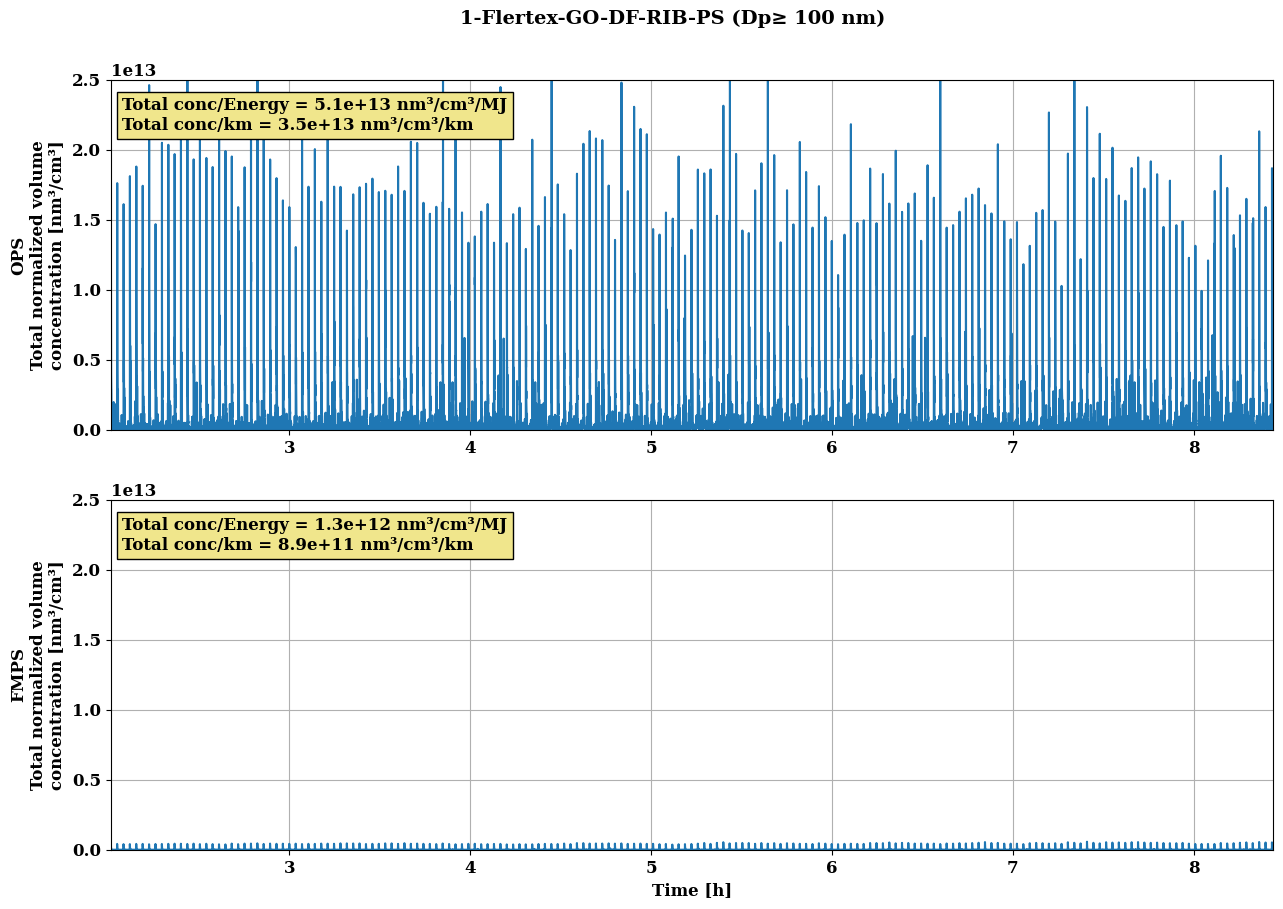

In [641]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=15,h=10)

fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#TPC_OPS
ax[0].plot(EP_OPS_out_volume_limit.index/3600,EP_OPS_out_volume_limit.sum(axis=1),label='Total volume concentration')
ax[0].set_ylabel('OPS\nTotal normalized volume\nconcentration [nm³/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
# ax[0].set_xlim(low_limit,high_limit)
ax[0].set_ylim(0,2.5E13)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
#ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[0].grid()

total_concentration_sum_1N = EP_OPS_out_volume_limit.sum(axis=1).sum(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} nm³/cm³".replace("+0", "").replace("-0", "-")
sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance:.1e} nm³/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy:.1e} nm³/cm³/MJ".replace("+0", "").replace("-0", "-")

ax[0].text(x=0.01,y=0.95,s=sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_volume_limit.index/3600,EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].sum(axis=1),label='Speed [rpm]', color='tab:blue')
ax[1].margins(x=0)
# ax[1].set_xlim(low_limit,high_limit)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized volume\nconcentration [nm³/cm³]', fontweight='bold', size=12)
ax[1].set_ylim(0,2.5E13)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid()

total_concentration_sum_2N = EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].sum(axis=1).sum(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} nm³/cm³".replace("+0", "").replace("-0", "-")
sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance:.1e} nm³/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy:.1e} nm³/cm³/MJ".replace("+0", "").replace("-0", "-")
ax[1].text(x=0.01,y=0.95,s=sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)


#### Modes en volume (Dp >= 100 nm & above threshold time)

In [642]:
mean_peaks_OPS = []
peaks_value_OPS = []

#OPS-Cal percentile
df_OPS_Mean=EP_OPS_out_volume_limit.mean(axis=0)

for i in range(1,len(EP_OPS_out_volume_limit.columns)-1):
    cond1 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i-1]
    cond2 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_volume_limit.columns.astype(float)[i]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i])
    cond1=i==1
    cond2=df_OPS_Mean.iloc[i-1]>df_OPS_Mean.iloc[i]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_volume_limit.columns.astype(float)[i-1]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i-1])

In [643]:
mean_peaks_corr=[]
peaks_value_corr = []

#FMPS-Cal percentile
df_FMPS_Mean_corr=EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].mean()
df_FMPS_Median_corr=EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].median()
df_FMPS_Sum_corr=EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].sum()
df_FMPS_10th_corr=EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].quantile(q=0.1)
df_FMPS_90th_corr=EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].quantile(q=0.9)

for i in range(1,len(EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].columns)-1):
    cond1 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i-1]
    cond2 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].columns.astype(float)[i])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i])
    cond1=i==1
    cond2=df_FMPS_Mean_corr.iloc[i-1]>df_FMPS_Mean_corr.iloc[i]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_volume_limit[EP_FMPS_out_volume_limit.columns[20:]].columns.astype(float)[i-1])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i-1]) 

Text(0.5, 0.95, '1-Flertex-GO-DF-RIB-PS (Dp≥ 100 nm)')

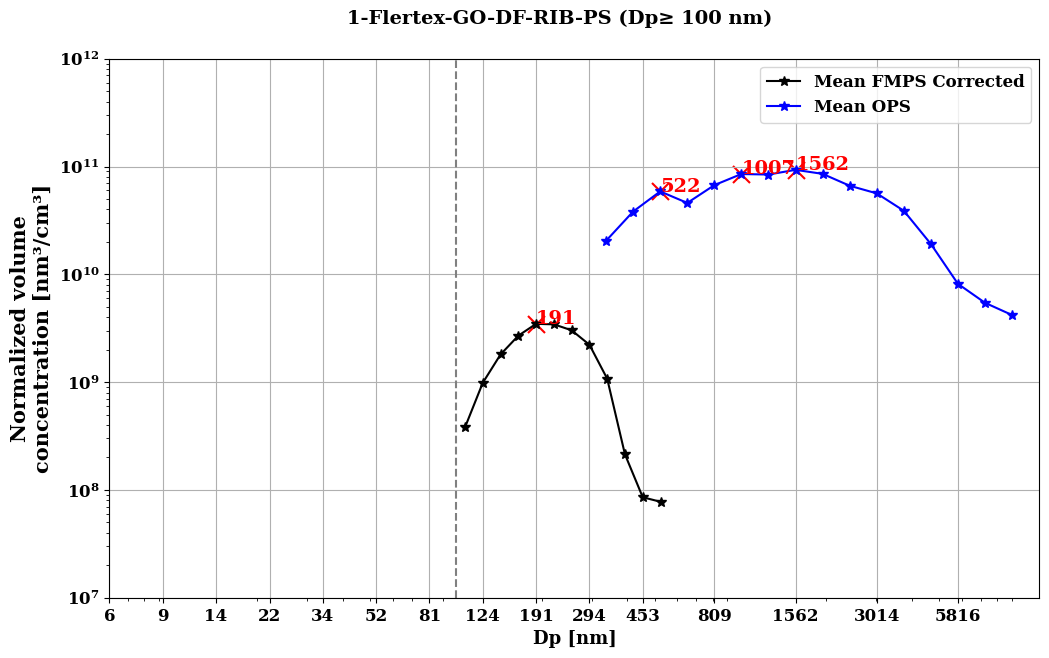

In [644]:
fig,ax = plt.subplots(nrows=1)
fig.set_size_inches(w=12,h=7)

label_EP = []
for i in range(len(EP_FMPS_out_volume_limit.columns)):
    label_EP.append(EP_FMPS_out_volume_limit.columns.astype(float)[i])
for i in range(3,len(EP_OPS_out_volume_limit.columns)):
    label_EP.append(EP_OPS_out_volume_limit.columns.astype(float)[i]*1000)

if not isinstance(ax, np.ndarray):
    ax = [ax]

#Plot FMPS corrected & OPS
ax[0].plot(EP_FMPS_out_volume_limit.columns[20:].astype(float),df_FMPS_Mean_corr, color ='k', marker='*', markersize=7, label='Mean FMPS Corrected')
ax[0].plot(EP_OPS_out_volume_limit.columns.astype(float)*1000,df_OPS_Mean, color ='b', marker='*', markersize=7, label='Mean OPS')
ax[0].set_ylabel('Normalized volume\nconcentration [nm³/cm³]',fontweight='bold', size=15)
ax[0].scatter(mean_peaks_corr,peaks_value_corr, c='red', marker = 'x', s=150)
ax[0].scatter(mean_peaks_OPS,peaks_value_OPS, c='red', marker = 'x', s=150)

for i in range(len(mean_peaks_corr)):
    ax[0].text(mean_peaks_corr[i],peaks_value_corr[i]+math.log(20),s=round(mean_peaks_corr[i]), fontsize=14, color='red')
for i in range(len(mean_peaks_OPS)):
    ax[0].text(mean_peaks_OPS[i],peaks_value_OPS[i]+math.log(20),s=round(mean_peaks_OPS[i]), fontsize=14, color='red')


for axes in ax:
    #for axes in axeses:
        axes.legend(ncol=1, loc='upper right')
        axes.grid()        
        axes.set_xscale('log')
        axes.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
        axes.set_xticks(label_EP[::3])
        #axes.set_ylim(0,6000)
        # axes.set_xlim(5,9016)

ax[0].set_xlabel('Dp [nm]', fontweight='bold', size=13)

ax[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax[0].axvline(x=100, color='gray', linestyle='--')
#y-scale_Log
ax[0].set_yscale('log') 
ax[0].set_ylim(1e7, 1e12)  
fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#fig.savefig(chemin_image)

#### Conc en mass (Dp >= 100 nm & above threshold time)

(2.0125, 8.438611111111111)

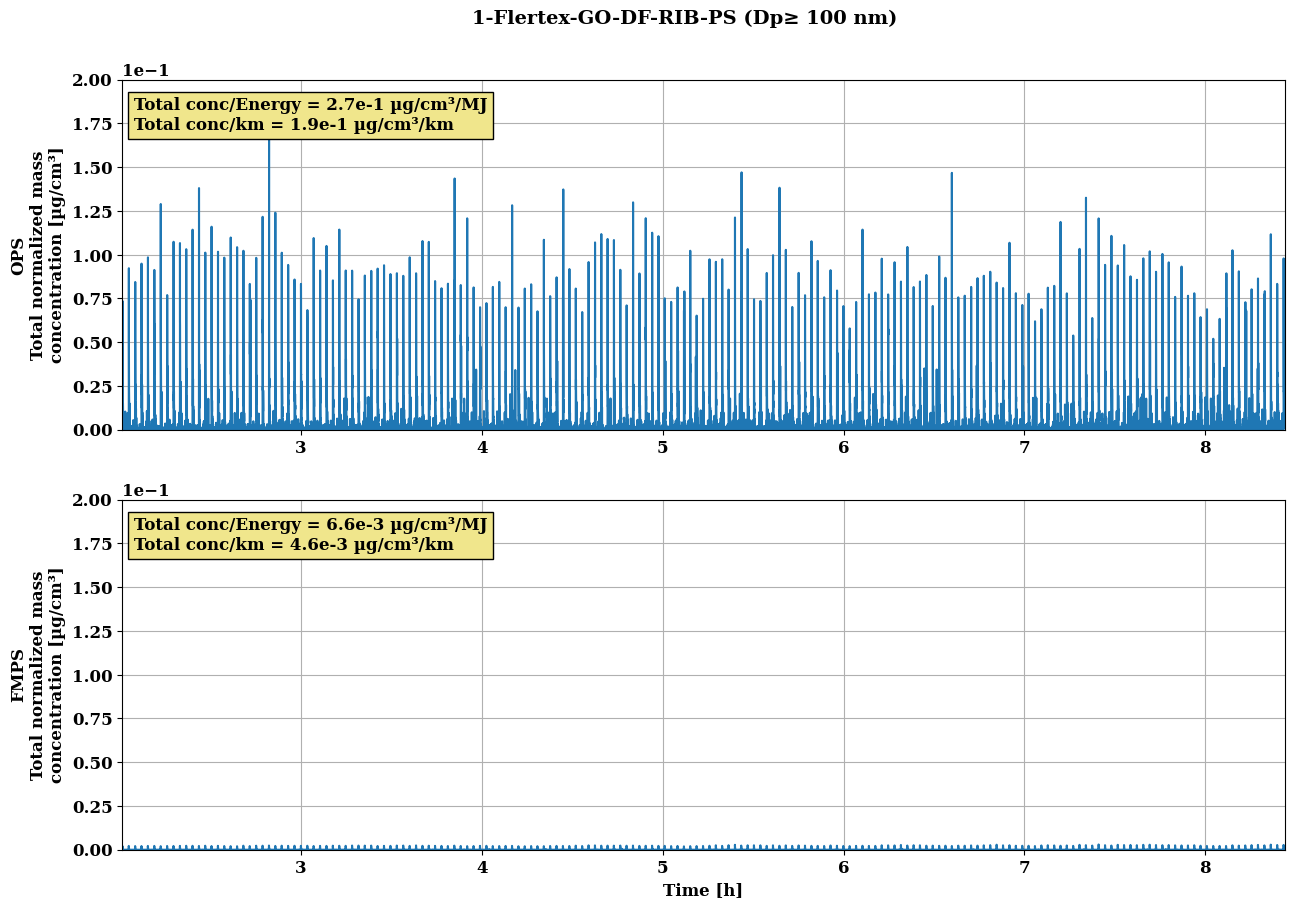

In [645]:
fig,ax = plt.subplots(nrows=2)
fig.set_size_inches(w=15,h=10)

fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#TPC_OPS
ax[0].plot(EP_OPS_out_mass_limit.index/3600,EP_OPS_out_mass_limit.sum(axis=1),label='Total mass concentration')
ax[0].set_ylabel('OPS\nTotal normalized mass\nconcentration [µg/cm³]', fontweight='bold', size=12)
ax[0].margins(x=0)
# ax[0].set_xlim(low_limit,high_limit)
ax[0].set_ylim(0,0.2)
ax[0].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
#ax[0].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[0].grid()

total_concentration_sum_1N = EP_OPS_out_mass_limit.sum(axis=1).sum(axis=0)
sum_text_1N = f"Total conc = {total_concentration_sum_1N:.1e} µg/cm³".replace("+0", "").replace("-0", "-")
sum_text_1N_km = f"Total conc/km = {total_concentration_sum_1N/total_distance:.1e} µg/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_1N_MJ = f"Total conc/Energy = {total_concentration_sum_1N/total_energy:.1e} µg/cm³/MJ".replace("+0", "").replace("-0", "-")

ax[0].text(x=0.01,y=0.95,s=sum_text_1N_MJ+'\n'+sum_text_1N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[0].transAxes, va='top', ha ='left')

#TPC_FMPS
ax[1].plot(EP_FMPS_out_mass_limit.index/3600,EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].sum(axis=1),label='Speed [rpm]', color='tab:blue')
ax[1].margins(x=0)
# ax[1].set_xlim(low_limit,high_limit)
ax[1].set_xlabel('Time [h]', fontweight='bold', size=12)
ax[1].set_ylabel('FMPS\nTotal normalized mass\nconcentration [µg/cm³]', fontweight='bold', size=12)
ax[1].set_ylim(0,0.2)
ax[1].ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax[1].grid()

total_concentration_sum_2N = EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].sum(axis=1).sum(axis=0)
sum_text_2N = f"Total conc = {total_concentration_sum_2N:.1e} µg/cm³".replace("+0", "").replace("-0", "-")
sum_text_2N_km = f"Total conc/km = {total_concentration_sum_2N/total_distance:.1e} µg/cm³/km".replace("+0", "").replace("-0", "-")
sum_text_2N_MJ = f"Total conc/Energy = {total_concentration_sum_2N/total_energy:.1e} µg/cm³/MJ".replace("+0", "").replace("-0", "-")
ax[1].text(x=0.01,y=0.95,s=sum_text_2N_MJ+'\n'+sum_text_2N_km,bbox={'facecolor':'khaki', 'edgecolor':'black'},transform = ax[1].transAxes, va='top', ha ='left')

xlim = ax[1].get_xlim()
ax[0].set_xlim(xlim)


#### Modes en mass (Dp >= 100 nm & above threshold time)

In [646]:
mean_peaks_OPS = []
peaks_value_OPS = []

#OPS-Cal percentile
df_OPS_Mean=EP_OPS_out_mass_limit.mean(axis=0)

for i in range(1,len(EP_OPS_out_mass_limit.columns)-1):
    cond1 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i-1]
    cond2 = df_OPS_Mean.iloc[i]>df_OPS_Mean.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_mass_limit.columns.astype(float)[i]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i])
    cond1=i==1
    cond2=df_OPS_Mean.iloc[i-1]>df_OPS_Mean.iloc[i]
    if cond1 & cond2:
        mean_peaks_OPS.append(EP_OPS_out_mass_limit.columns.astype(float)[i-1]*1000)
        peaks_value_OPS.append(df_OPS_Mean.iloc[i-1])

In [647]:
mean_peaks_corr=[]
peaks_value_corr = []

#FMPS-Cal percentile
df_FMPS_Mean_corr=EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].mean()
df_FMPS_Median_corr=EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].median()
df_FMPS_Sum_corr=EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].sum()
df_FMPS_10th_corr=EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].quantile(q=0.1)
df_FMPS_90th_corr=EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].quantile(q=0.9)

for i in range(1,len(EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].columns)-1):
    cond1 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i-1]
    cond2 = df_FMPS_Mean_corr.iloc[i]>df_FMPS_Mean_corr.iloc[i+1]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].columns.astype(float)[i])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i])
    cond1=i==1
    cond2=df_FMPS_Mean_corr.iloc[i-1]>df_FMPS_Mean_corr.iloc[i]
    if cond1 & cond2:
        mean_peaks_corr.append(EP_FMPS_out_mass_limit[EP_FMPS_out_mass_limit.columns[20:]].columns.astype(float)[i-1])
        peaks_value_corr.append(df_FMPS_Mean_corr.iloc[i-1]) 

Text(0.5, 0.95, '1-Flertex-GO-DF-RIB-PS (Dp≥ 100 nm)')

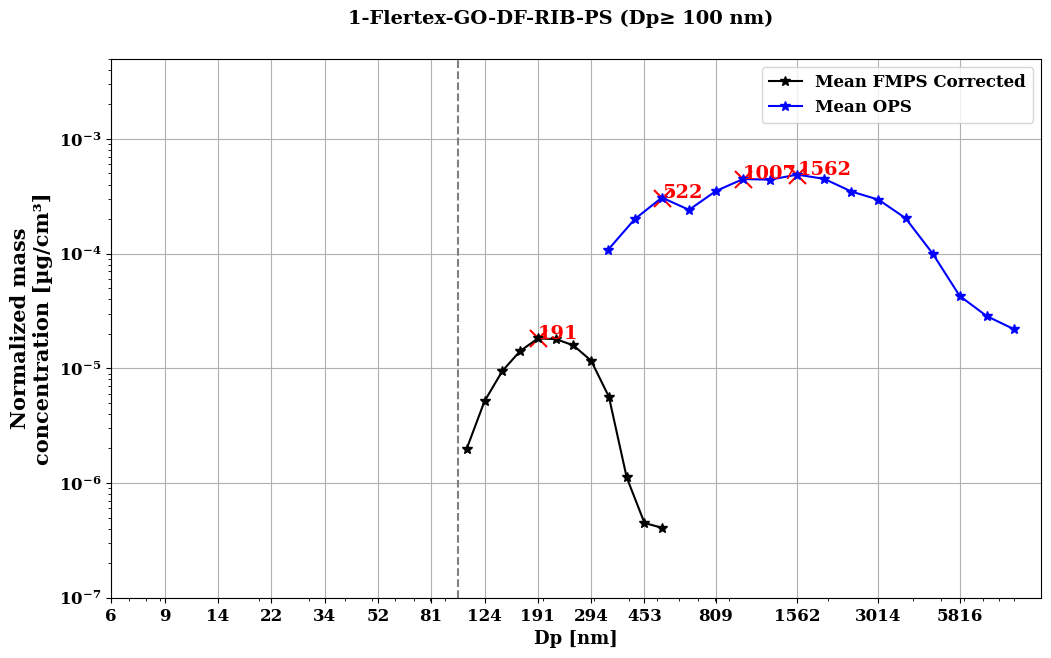

In [648]:
fig,ax = plt.subplots(nrows=1)
fig.set_size_inches(w=12,h=7)

label_EP = []
for i in range(len(EP_FMPS_out_mass_limit.columns)):
    label_EP.append(EP_FMPS_out_mass_limit.columns.astype(float)[i])
for i in range(3,len(EP_OPS_out_mass_limit.columns)):
    label_EP.append(EP_OPS_out_mass_limit.columns.astype(float)[i]*1000)

if not isinstance(ax, np.ndarray):
    ax = [ax]

#Plot FMPS corrected & OPS
ax[0].plot(EP_FMPS_out_mass_limit.columns[20:].astype(float),df_FMPS_Mean_corr, color ='k', marker='*', markersize=7, label='Mean FMPS Corrected')
ax[0].plot(EP_OPS_out_mass_limit.columns.astype(float)*1000,df_OPS_Mean, color ='b', marker='*', markersize=7, label='Mean OPS')
ax[0].set_ylabel('Normalized mass\nconcentration [µg/cm³]',fontweight='bold', size=15)
ax[0].scatter(mean_peaks_corr,peaks_value_corr, c='red', marker = 'x', s=150)
ax[0].scatter(mean_peaks_OPS,peaks_value_OPS, c='red', marker = 'x', s=150)

for i in range(len(mean_peaks_corr)):
    ax[0].text(mean_peaks_corr[i],peaks_value_corr[i],s=round(mean_peaks_corr[i]), fontsize=14, color='red')
for i in range(len(mean_peaks_OPS)):
    ax[0].text(mean_peaks_OPS[i],peaks_value_OPS[i],s=round(mean_peaks_OPS[i]), fontsize=14, color='red')


for axes in ax:
    #for axes in axeses:
        axes.legend(ncol=1, loc='upper right')
        axes.grid()        
        axes.set_xscale('log')
        axes.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
        axes.set_xticks(label_EP[::3])
        #axes.set_ylim(0,6000)
        # axes.set_xlim(5,9016)

ax[0].set_xlabel('Dp [nm]', fontweight='bold', size=13)

ax[0].yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax[0].axvline(x=100, color='gray', linestyle='--')
#y-scale_Log
ax[0].set_yscale('log') 
ax[0].set_ylim(1e-7, 5e-3)  
fig.suptitle(fig_title_2, fontweight='bold', size=14, y=0.95) 

#fig.savefig(chemin_image)